# OLBI Dataset — Preprocessing and Target Construction

## Purpose

This notebook implements the preprocessing pipeline for the OLBI dataset
used in the study.

The main objectives are to:

1. Load and inspect the original participant-level dataset.
2. Prepare and correctly score the OLBI burnout items.
3. Transform the instrument-level burnout score into the study's
   Harmonised Burnout Score (HBS).
4. Construct the binary burnout-risk target for supervised classification.
5. Identify and prepare appropriate workplace and demographic predictor variables.
6. Prevent target leakage by excluding variables used to construct the burnout outcome.
7. Prepare the cleaned dataset for exploratory analysis and subsequent modelling.

The original dataset assessment is retained separately to preserve the
dataset-screening and selection process.

In [6]:
%pip install pyreadstat

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyreadstat

In [8]:
dataset, metadata = pyreadstat.read_sav(
    "/Users/cristinaabrahamse/Documents/Eduvos University/Data Science Honours /Early Prediction of Burnout (Honours Proj.)/Burnout Datasets (Raw)/OLBI_original_Mendeley_data.sav"
 )

In [9]:
print("Dataset shape:", dataset.shape)
dataset.head()

Dataset shape: (617, 26)


,Timeline,olbi1,olbi2,olbi3,olbi4,olbi5,olbi6,olbi7,olbi8,olbi9,...,olbi16,Gender,Age,Education_level,Job_description,Full_Part_time,Public_Private_Sector,Hire_year,tenure,Job_position
0,2014-07-05,2.0,2.0,4.0,3.0,3.0,4.0,2.0,2.0,3.0,...,2.0,1.0,1968.0,2.0,ΣΤΕΛΕΧΟΣ ΕΠΙΧ/ΣΗΣ,Πλήρη απασχόληση,Ιδιωτικός,1993,ΑΠΟ 1 ΜΕΧΡΙ 12,Είμαι προϊστάμενος/ η
1,2014-07-07,3.0,1.0,2.0,2.0,3.0,2.0,3.0,1.0,2.0,...,3.0,1.0,1974.0,5.0,ΙΔΙΩΤΙΚΟΣ ΥΠΑΛΛΗΛΟΣ,Πλήρη απασχόληση,Ιδιωτικός,2009,5,Είμαι υφιστάμενος/ η
2,2014-07-24,1.0,3.0,4.0,1.0,2.0,3.0,2.0,3.0,2.0,...,2.0,1.0,1979.0,6.0,Χημικός Μηχανικός,Πλήρη απασχόληση,Ιδιωτικός,2012,2 χρόνια,Είμαι προϊστάμενος/ η
3,2014-07-24,1.0,2.0,4.0,3.0,1.0,3.0,1.0,3.0,1.0,...,2.0,1.0,1975.0,5.0,Μηχανικός,Πλήρη απασχόληση,Ιδιωτικός,2014,3 μήνες με υφιστάμενους,Είμαι προϊστάμενος/ η
4,2014-07-25,2.0,3.0,3.0,3.0,2.0,4.0,1.0,3.0,2.0,...,2.0,1.0,1988.0,5.0,ΙΔΙΩΤΙΚΟΣ ΥΠΑΛΛΗΛΟΣ,Πλήρη απασχόληση,Ιδιωτικός,2012,2,Είμαι υφιστάμενος/ η


In [10]:
# Create a working copy for preprocessing
olbi = dataset.copy()

print("Original dataset shape:", dataset.shape)
print("Working copy shape:", olbi.shape)

Original dataset shape: (617, 26)
Working copy shape: (617, 26)


In [11]:
# Identify the 16 OLBI questionnaire items
olbi_items = [f"olbi{i}" for i in range(1, 17)]

print("Number of OLBI items:", len(olbi_items))
print(olbi_items)

Number of OLBI items: 16
['olbi1', 'olbi2', 'olbi3', 'olbi4', 'olbi5', 'olbi6', 'olbi7', 'olbi8', 'olbi9', 'olbi10', 'olbi11', 'olbi12', 'olbi13', 'olbi14', 'olbi15', 'olbi16']


In [12]:
# Check for missing values in the OLBI items
olbi[olbi_items].isnull().sum()

olbi1     0
olbi2     0
olbi3     0
olbi4     0
olbi5     0
olbi6     0
olbi7     0
olbi8     0
olbi9     0
olbi10    0
olbi11    0
olbi12    0
olbi13    0
olbi14    0
olbi15    0
olbi16    0
dtype: int64

In [13]:
# Check the observed response range for each OLBI item
olbi[olbi_items].agg(["min", "max"])

,olbi1,olbi2,olbi3,olbi4,olbi5,olbi6,olbi7,olbi8,olbi9,olbi10,olbi11,olbi12,olbi13,olbi14,olbi15,olbi16
min,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
max,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0,4.0


In [14]:
# OLBI items requiring reverse scoring
reverse_items = [
    "olbi2", "olbi3", "olbi4", "olbi6",
    "olbi8", "olbi9", "olbi11", "olbi12"
]

# Reverse score the required items on the 1–4 scale
for item in reverse_items:
    olbi[item + "_scored"] = 5 - olbi[item]

print("Reverse-scored items created:")
print([item + "_scored" for item in reverse_items])

Reverse-scored items created:
['olbi2_scored', 'olbi3_scored', 'olbi4_scored', 'olbi6_scored', 'olbi8_scored', 'olbi9_scored', 'olbi11_scored', 'olbi12_scored']


In [15]:
# Create scored versions of the OLBI items that do not require reversal
for item in olbi_items:
    scored_item = item + "_scored"

    if item not in reverse_items:
        olbi[scored_item] = olbi[item]

# List all scored OLBI variables
scored_olbi_items = [item + "_scored" for item in olbi_items]

print("Number of scored OLBI items:", len(scored_olbi_items))
print(scored_olbi_items)

Number of scored OLBI items: 16
['olbi1_scored', 'olbi2_scored', 'olbi3_scored', 'olbi4_scored', 'olbi5_scored', 'olbi6_scored', 'olbi7_scored', 'olbi8_scored', 'olbi9_scored', 'olbi10_scored', 'olbi11_scored', 'olbi12_scored', 'olbi13_scored', 'olbi14_scored', 'olbi15_scored', 'olbi16_scored']


In [16]:
# Define the two OLBI dimensions using the scored items
exhaustion_items = [
    "olbi2_scored", "olbi4_scored", "olbi5_scored", "olbi8_scored",
    "olbi10_scored", "olbi12_scored", "olbi14_scored", "olbi16_scored"
]

disengagement_items = [
    "olbi1_scored", "olbi3_scored", "olbi6_scored", "olbi7_scored",
    "olbi9_scored", "olbi11_scored", "olbi13_scored", "olbi15_scored"
]

print("Exhaustion items:", len(exhaustion_items))
print("Disengagement items:", len(disengagement_items))

Exhaustion items: 8
Disengagement items: 8


In [17]:
# Calculate mean scores for the two OLBI dimensions
olbi["OLBI_Exhaustion"] = olbi[exhaustion_items].mean(axis=1)
olbi["OLBI_Disengagement"] = olbi[disengagement_items].mean(axis=1)

# Display the first 10 calculated scores
olbi[["OLBI_Exhaustion", "OLBI_Disengagement"]].head(10)

,OLBI_Exhaustion,OLBI_Disengagement
0,2.500,1.875
1,3.125,3.125
2,2.000,1.625
3,2.000,1.625
4,2.000,1.875
5,1.125,1.750
6,2.125,1.375
7,1.750,2.125
8,2.125,1.750
9,2.125,2.000


In [18]:
# Check the range and summary statistics of the OLBI dimensions
olbi[["OLBI_Exhaustion", "OLBI_Disengagement"]].describe()

,OLBI_Exhaustion,OLBI_Disengagement
count,617.000000,617.000000
mean,2.156605,1.968193
std,0.568032,0.499011
min,1.000000,1.000000
25%,1.750000,1.625000
50%,2.125000,1.875000
75%,2.500000,2.250000
max,4.000000,3.750000


In [19]:
# Calculate the overall OLBI mean from all 16 correctly scored items
olbi["OLBI_Overall"] = olbi[scored_olbi_items].mean(axis=1)

# Inspect the resulting score
olbi["OLBI_Overall"].describe()

count    617.000000
mean       2.062399
std        0.464298
min        1.062500
25%        1.687500
50%        2.062500
75%        2.375000
max        3.750000
Name: OLBI_Overall, dtype: float64

In [20]:
# Transform the overall OLBI score to the 0–100 Harmonised Burnout Score (HBS)
olbi["HBS"] = (
    (olbi["OLBI_Overall"] - 1) / (4 - 1)
) * 100

# Inspect the HBS
olbi["HBS"].describe()

count    617.000000
mean      35.413290
std       15.476613
min        2.083333
25%       22.916667
50%       35.416667
75%       45.833333
max       91.666667
Name: HBS, dtype: float64

In [21]:
# Calculate the dataset-specific 75th percentile threshold
hbs_threshold = olbi["HBS"].quantile(0.75)

# Create the binary burnout-risk target
olbi["Burnout_Risk"] = (olbi["HBS"] >= hbs_threshold).astype(int)

print("HBS 75th percentile threshold:", hbs_threshold)

print("\nBurnout risk counts:")
print(olbi["Burnout_Risk"].value_counts().sort_index())

HBS 75th percentile threshold: 45.83333333333333

Burnout risk counts:
Burnout_Risk
0    447
1    170
Name: count, dtype: int64


In [22]:
# Identify original non-OLBI variables as candidate predictors
candidate_predictors = [
    col for col in dataset.columns
    if col not in olbi_items
]

print("Number of candidate predictor variables:", len(candidate_predictors))

for col in candidate_predictors:
    print(col)

Number of candidate predictor variables: 10
Timeline
Gender
Age
Education_level
Job_description
Full_Part_time
Public_Private_Sector
Hire_year
tenure
Job_position


In [23]:
# Display available metadata for each candidate predictor
for col in candidate_predictors:
    print("=" * 60)
    print("Variable:", col)
    print("Label:", metadata.column_names_to_labels.get(col))
    
    if col in metadata.variable_value_labels:
        print("Value labels:", metadata.variable_value_labels[col])
    else:
        print("Value labels: None")

Variable: Timeline
Label: Χρονική σήμανση
Value labels: None
Variable: Gender
Label: None
Value labels: {1.0: 'Male', 2.0: 'Female'}
Variable: Age
Label: None
Value labels: None
Variable: Education_level
Label: None
Value labels: {1.0: 'Basic school education', 2.0: 'High School/Lykeion', 3.0: 'TEchnical Education', 4.0: 'College/BA/TEI', 5.0: 'College/BA/AEI', 6.0: 'Postgraduate Education'}
Variable: Job_description
Label: None
Value labels: None
Variable: Full_Part_time
Label: None
Value labels: None
Variable: Public_Private_Sector
Label: None
Value labels: None
Variable: Hire_year
Label: None
Value labels: None
Variable: tenure
Label: Πόσο καιρό συνεργάζεστε με τον/ την προϊστάμενο/ η ή αντίστοιχα με τους υφιστάμενους ;
Value labels: None
Variable: Job_position
Label: Leaders/Followers
Value labels: None


In [24]:
# Build a structured metadata table for LLM-assisted variable mapping
llm_input = []

for col in candidate_predictors:
    llm_input.append({
        "Variable": col,
        "Label": metadata.column_names_to_labels.get(col),
        "Value_Labels": metadata.variable_value_labels.get(col)
    })

llm_input = pd.DataFrame(llm_input)

llm_input

,Variable,Label,Value_Labels
0,Timeline,Χρονική σήμανση,None
1,Gender,None,"{1.0: 'Male', 2.0: 'Female'}"
2,Age,None,None
3,Education_level,None,"{1.0: 'Basic school education', 2.0: 'High Sch..."
4,Job_description,None,None
5,Full_Part_time,None,None
6,Public_Private_Sector,None,None
7,Hire_year,None,None
8,tenure,Πόσο καιρό συνεργάζεστε με τον/ την προϊστάμεν...,None
9,Job_position,Leaders/Followers,None


In [25]:
# Add example values from each candidate predictor for LLM context
example_values = []

for col in candidate_predictors:
    examples = dataset[col].dropna().astype(str).unique()[:5]
    example_values.append(list(examples))

llm_input["Example_Values"] = example_values

llm_input

,Variable,Label,Value_Labels,Example_Values
0,Timeline,Χρονική σήμανση,None,"[2014-07-05, 2014-07-07, 2014-07-24, 2014-07-2..."
1,Gender,None,"{1.0: 'Male', 2.0: 'Female'}","[1.0, 2.0]"
2,Age,None,None,"[1968.0, 1974.0, 1979.0, 1975.0, 1988.0]"
3,Education_level,None,"{1.0: 'Basic school education', 2.0: 'High Sch...","[2.0, 5.0, 6.0, 4.0, 3.0]"
4,Job_description,None,None,"[ΣΤΕΛΕΧΟΣ ΕΠΙΧ/ΣΗΣ, ΙΔΙΩΤΙΚΟΣ ΥΠΑΛΛΗΛΟΣ, Χημικ..."
5,Full_Part_time,None,None,"[Πλήρη απασχόληση, Μερική απασχόληση, Ειδικό π..."
6,Public_Private_Sector,None,None,"[Ιδιωτικός, Δημόσιος, ΣΤΡΑΤΙΩΤΙΚΟ, ΝΠΔΔ, ΔΗΜΟΣ..."
7,Hire_year,None,None,"[1993, 2009, 2012, 2014, 2010]"
8,tenure,Πόσο καιρό συνεργάζεστε με τον/ την προϊστάμεν...,None,"[ΑΠΟ 1 ΜΕΧΡΙ 12, 5, 2 χρόνια, 3 μήνες με υφιστ..."
9,Job_position,Leaders/Followers,None,"[Είμαι προϊστάμενος/ η, Είμαι υφιστάμενος/ η, ]"


## LLM-Assisted Predictor Mapping — OLBI Dataset

The available variable names, SPSS metadata, value labels and representative
values were provided as contextual information for LLM-assisted semantic
mapping.

The LLM was used to propose common conceptual groups for the candidate
predictor variables. The LLM was not used to determine statistical importance,
construct the burnout outcome or make final feature-selection decisions.

### Proposed LLM Mapping

| Variable | Proposed Common Construct | Proposed Role | Confidence | Validation Note |
|---|---|---|---|---|
| Timeline | Data Collection / Temporal Metadata | Exclude | High | Appears to represent data-collection timing rather than a workplace predictor. |
| Gender | Demographics | Candidate predictor | High | Gender coding is documented in the SPSS metadata. |
| Age | Demographics | Candidate predictor | High | Representative values resemble years of birth rather than chronological age; transformation must be investigated. |
| Education_level | Demographics / Education | Candidate predictor | High | Education categories are documented in the SPSS metadata. |
| Job_description | Occupational Characteristics | Candidate predictor | High | Represents occupation/job description; Greek values require interpretation before encoding. |
| Full_Part_time | Employment Characteristics | Candidate predictor | High | Representative values indicate full-time/part-time employment. |
| Public_Private_Sector | Employment Characteristics | Candidate predictor | High | Representative values indicate employment-sector categories. |
| Hire_year | Employment History / Tenure | Candidate predictor | High | Represents year employment began. |
| tenure | Employment History / Tenure | Candidate predictor | High | Available Greek label and values suggest duration of working relationship; exact interpretation requires validation. |
| Job_position | Occupational Characteristics / Leadership Role | Candidate predictor | High | SPSS label identifies Leaders/Followers and values indicate supervisory status. |

### Researcher Validation

All LLM-proposed mappings will be reviewed against the available dataset
metadata, questionnaire information and observed variable values before the
variables are included in the final modelling dataset.

The LLM mapping therefore serves as semantic assistance rather than an
automated feature-selection mechanism.

In [26]:
# Investigate the Age variable and data-collection timeline

print("Age variable summary:")
print(dataset["Age"].describe())

print("\nTimeline range:")
print("Earliest:", dataset["Timeline"].min())
print("Latest:", dataset["Timeline"].max())

print("\nExample Age and Timeline values:")
display(dataset[["Age", "Timeline"]].head(10))

Age variable summary:
count     575.000000
mean     1969.840000
std         9.011344
min      1939.000000
25%      1963.000000
50%      1970.000000
75%      1976.000000
max      1993.000000
Name: Age, dtype: float64

Timeline range:
Earliest: 2014-07-05
Latest: 2015-02-14

Example Age and Timeline values:


,Age,Timeline
0,1968.0,2014-07-05
1,1974.0,2014-07-07
2,1979.0,2014-07-24
3,1975.0,2014-07-24
4,1988.0,2014-07-25
5,1977.0,2014-07-25
6,1983.0,2014-07-25
7,1981.0,2014-07-29
8,1970.0,2014-08-01
9,1959.0,2014-08-01


In [27]:
# Convert Timeline to a date
olbi["Timeline"] = pd.to_datetime(olbi["Timeline"])

# Preserve the original Age variable as year of birth
olbi["Birth_Year"] = olbi["Age"]

# Calculate approximate age at the time of data collection
olbi["Age_Calculated"] = (
    olbi["Timeline"].dt.year - olbi["Birth_Year"]
)

# Inspect the calculated age
olbi["Age_Calculated"].describe()

count    575.000000
mean      44.606957
std        9.098108
min       21.000000
25%       38.000000
50%       45.000000
75%       52.000000
max       76.000000
Name: Age_Calculated, dtype: float64

In [28]:
# Investigate employment-history variables

print("Hire_year summary:")
print(dataset["Hire_year"].describe())

print("\nHire_year missing values:")
print(dataset["Hire_year"].isnull().sum())

print("\nTenure example values and frequencies:")
print(dataset["tenure"].value_counts(dropna=False).head(20))

Hire_year summary:
count      617
unique      55
top       2012
freq        53
Name: Hire_year, dtype: object

Hire_year missing values:
0

Tenure example values and frequencies:
tenure
3                      22
2                      19
ΚΕΝΟ - ΧΕΙΡΟΓΡΑΦΟ      18
10 ΧΡΟΝΙΑ              18
3 ΧΡΟΝΙΑ               15
2 χρόνια ΧΕΙΡΟΓΡΑΦΟ    15
10 ΕΤΗ  ΧΕΙΡΟΓΡΑΦΟ     14
5 ΧΡΟΝΙΑ               11
1                      11
2 ΧΡΟΝΙΑ               11
5                       9
10 ΕΤΗ                  9
10                      9
1 ΕΤΟΣ                  9
20                      9
1 ΧΡΟΝΟ- ΧΕΙΡΟΓΡΑΦΟ     8
                        7
6                       7
20 ΧΡΟΝΙΑ               6
4 ΧΡΟΝΙΑ                6
Name: count, dtype: int64


In [29]:
# Convert Hire_year temporarily to numeric for inspection
hire_year_numeric = pd.to_numeric(dataset["Hire_year"], errors="coerce")

print("Hire year summary:")
print(hire_year_numeric.describe())

print("\nValues that could not be converted to a year:")
print(hire_year_numeric.isnull().sum())

print("\nEarliest hire years:")
print(hire_year_numeric.sort_values().head(10).tolist())

print("\nLatest hire years:")
print(hire_year_numeric.sort_values().tail(10).tolist())

Hire year summary:
count     594.000000
mean     2002.028620
std         9.462495
min      1970.000000
25%      1996.000000
50%      2004.000000
75%      2010.000000
max      2031.000000
Name: Hire_year, dtype: float64

Values that could not be converted to a year:
23

Earliest hire years:
[1970.0, 1970.0, 1972.0, 1977.0, 1977.0, 1978.0, 1978.0, 1979.0, 1980.0, 1980.0]

Latest hire years:
[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]


In [30]:
# Inspect Hire_year values that could not be converted to numeric
invalid_hire_years = dataset.loc[
    hire_year_numeric.isnull(),
    "Hire_year"
]

print("Invalid Hire_year entries:")
print(invalid_hire_years.value_counts(dropna=False))

Invalid Hire_year entries:
Hire_year
ΚΕΝΟ                                     7
                                         4
01/04/2014                               1
1 ΜΗΝΑ                                   1
3 ΧΡΟΝΙΑ                                 1
KENO                                     1
ΕΜΠΟΡΟΣ 2013 ΣΥΜΒΟΥΛΟΣ 2000              1
15/07/2014                               1
35 ΧΡΟΝΙΑ                                1
1978 ΔΙΟΡΙΣΜΟΣ 2006 ΣΥΓΚΕΚΡΙΜΕΝΗ ΘΕΣΗ    1
8/01/2014                                1
01/11/2011                               1
2008-2006                                1
2000-2015                                1
Name: count, dtype: int64


In [31]:
# Create a numeric hire-year variable
olbi["Hire_Year_Numeric"] = pd.to_numeric(
    olbi["Hire_year"],
    errors="coerce"
)

# Calculate employment duration at the time of data collection
olbi["Employment_Duration"] = (
    olbi["Timeline"].dt.year - olbi["Hire_Year_Numeric"]
)

# Inspect the calculated employment duration
olbi["Employment_Duration"].describe()

count    594.000000
mean      12.427609
std        9.525097
min      -17.000000
25%        4.000000
50%       10.000000
75%       18.750000
max       45.000000
Name: Employment_Duration, dtype: float64

In [32]:
# Identify impossible negative employment-duration values
invalid_duration = olbi.loc[
    olbi["Employment_Duration"] < 0,
    ["Timeline", "Hire_year", "Hire_Year_Numeric", "Employment_Duration"]
]

print("Number of negative employment-duration records:", len(invalid_duration))

display(invalid_duration)

Number of negative employment-duration records: 1


,Timeline,Hire_year,Hire_Year_Numeric,Employment_Duration
208,2014-10-01,2031,2031.0,-17.0


In [33]:
# Mark impossible hire-year values as missing
invalid_hire_mask = (
    olbi["Hire_Year_Numeric"] > olbi["Timeline"].dt.year
)

olbi.loc[
    invalid_hire_mask,
    ["Hire_Year_Numeric", "Employment_Duration"]
] = np.nan

# Recheck employment duration
olbi["Employment_Duration"].describe()

count    593.000000
mean      12.477234
std        9.455974
min        0.000000
25%        4.000000
50%       10.000000
75%       19.000000
max       45.000000
Name: Employment_Duration, dtype: float64

In [34]:
# Inspect unique tenure values

tenure_values = (
    dataset["tenure"]
    .dropna()
    .astype(str)
    .value_counts()
)

print("Number of unique tenure values:", tenure_values.shape[0])

display(tenure_values.head(50))

Number of unique tenure values: 293


tenure
3                         22
2                         19
ΚΕΝΟ - ΧΕΙΡΟΓΡΑΦΟ         18
10 ΧΡΟΝΙΑ                 18
3 ΧΡΟΝΙΑ                  15
2 χρόνια ΧΕΙΡΟΓΡΑΦΟ       15
10 ΕΤΗ  ΧΕΙΡΟΓΡΑΦΟ        14
5 ΧΡΟΝΙΑ                  11
1                         11
2 ΧΡΟΝΙΑ                  11
5                          9
10 ΕΤΗ                     9
10                         9
1 ΕΤΟΣ                     9
20                         9
1 ΧΡΟΝΟ- ΧΕΙΡΟΓΡΑΦΟ        8
                           7
6                          7
20 ΧΡΟΝΙΑ                  6
4 ΧΡΟΝΙΑ                   6
7 ΧΡΟΝΙΑ                   6
6 ΜΗΝΕΣ                    6
15                         6
4                          6
6 ΧΡΟΝΙΑ ΧΕΙΡΟΓΡΑΦΟ        6
6 ΧΡΟΝΙΑ                   5
3 ΧΡΟΝΙΑ ΧΕΙΡΟΓΡΑΦΟ        5
8 ΕΤΗ                      5
8                          5
20 ΧΡΟΝΙΑ - ΧΕΙΡΟΓΡΑΦΟ     5
7 ΧΡΟΝΙΑ - ΧΕΙΡΟΓΡΑΦΟ      4
2 χρόνια                   4
1 ΧΡΟΝΟ                    4
1,5                        4
4 ΧΡΟΝΙ

In [35]:
# Inspect the least frequent tenure responses
display(tenure_values.tail(60))

tenure
3 χρόνια με τους υφισταμένους                        1
3 ,5ΧΡΟΝΙΑ ΜΕ ΥΦΙΣΤΑΜΕΝΟΥΣ                           1
2 ΧΡΟΝΙΑ ΜΕ ΤΟΝ ΠΡΟΙΣΤΑΜΕΝΟ ΜΟΥ                      1
3 χρόνια με τον προϊστάμενό μου                      1
25 ΧΡΟΝΙΑ - ΧΕΙΡΟΓΡΑΦΟ                               1
13 ΧΡΟΝΙΑ - ΧΕΙΡΟΓΡΑΦΟ                               1
ΑΠΟ 2 ΧΡΟΝΙΑ ΕΩΣ14 - ΧΕΙΡΟΓΡΑΦΟ                      1
10-12 ΧΡΟΝΙΑ ΧΕΙΡΟΓΡΑΦΟ                              1
5-20 ΧΡΟΝΙΑ ΧΕΙΡΟΓΡΑΦΟ                               1
11 ΧΡΟΝΙΑ - ΧΕΙΡΟΓΡΑΦΟ                               1
5 ΜΗΝΕΣ ΧΕΙΡΟΓΡΑΦΟ                                   1
1993                                                 1
1 ΜΗΝΑ ΧΕΙΡΟΓΡΑΦΟ                                    1
15 ΜΗΝΕΣ ΧΕΙΡΟΓΡΑΦΟ                                  1
ΟΙΚΟΓΕΝΕΙΑΚΗ ΕΠΙΧΕΙΡΗΣΗ ΧΕΙΡΟΓΡΑΦΟ                   1
1-18 ΧΕΙΡΟΓΡΑΦΟ                                      1
ΧΡΟΝΙΑ ΧΕΙΡΟΓΡΑΦΟ                                    1
3 ΜΗΝΕΣ ΧΕΙΡΟΓΡΑΦΟ                                   1
6 Μ

### Researcher Validation — Tenure Variable

The LLM-assisted semantic mapping initially identified `tenure` as a potential
employment-history variable. Researcher validation showed that the variable
contained 293 unique free-text responses across 617 observations, including
numeric durations, durations expressed in months or years, ranges, dates,
handwritten-response indicators and ambiguous descriptive responses.

Because substantial interpretation and researcher-defined conversion rules
would be required to derive a consistent numeric measure, the raw `tenure`
variable was excluded from the candidate predictor set.

A separate employment-duration variable was derived from the more consistently
recorded `Hire_year` and data-collection year variables and retained as the
primary employment-duration measure.

In [36]:
for col in ["Gender", "Education_level"]:
    print("=" * 50)
    print("Variable:", col)
    print("Missing values:", olbi[col].isnull().sum())
    print("Unique values:", olbi[col].nunique(dropna=True))
    print("\nValue counts:")
    print(olbi[col].value_counts(dropna=False))
    print()

Variable: Gender
Missing values: 6
Unique values: 2

Value counts:
Gender
1.0    308
2.0    303
NaN      6
Name: count, dtype: int64

Variable: Education_level
Missing values: 2
Unique values: 6

Value counts:
Education_level
5.0    223
2.0    138
4.0    105
6.0     81
3.0     57
1.0     11
NaN      2
Name: count, dtype: int64



In [37]:
for col in ["Full_Part_time", "Public_Private_Sector"]:
    print("=" * 50)
    print("Variable:", col)
    print("Missing values:", olbi[col].isnull().sum())
    print("Unique values:", olbi[col].nunique(dropna=True))
    print("\nValue counts:")
    print(olbi[col].value_counts(dropna=False))
    print()

Variable: Full_Part_time
Missing values: 0
Unique values: 4

Value counts:
Full_Part_time
Πλήρη απασχόληση     584
Ειδικό πρόγραμμα      16
Μερική απασχόληση     12
                       5
Name: count, dtype: int64

Variable: Public_Private_Sector
Missing values: 0
Unique values: 21

Value counts:
Public_Private_Sector
Δημόσιος                     321
Ιδιωτικός                    268
                               8
ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓ                3
ΔΗΜΟΣΙΟΣ                       1
ΠΡΟΣΩΠΙΚΗ ΕΠΙΧΕΙΡΗΣΗ           1
ΕΠΙΧΕΙΡΗΣΗ                     1
ΤΟΠΙΚΗ ΑΥΤΟΔΙΟΙΚΗΣΗ            1
ΔΗΜΟΤΙΚΗ ΕΠΙΧΕΙΡΗΣΗ            1
ΝΠΙΔ                           1
ΔΗΜΟΤΙΚΟΣ                      1
ΙΔΙΟΚΤΗΤΗΣ ΦΡΟΝΤΙΣΤΗΡΙΟΥ       1
ΙΔΙΟΚΤΗΤΟ                      1
ΕΥΡΥΤΕΡΟΣ ΔΗΜΟΣΙΟΣ ΤΟΜΕΑΣ      1
ΑΜΚΕ                           1
ΣΤΡΑΤΙΩΤΙΚΟ                    1
ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓΕΛΜΑΤΙΑΣ        1
ΝΠΔΔ                           1
ΑΤΟΜΙΚΗ ΕΠΙΧΕΙΡΗΣΗ             1
ΚΕΝΟ                           1
ΜΙΚΤΟΣ            

In [38]:
for value, count in olbi["Public_Private_Sector"].value_counts(dropna=False).items():
    print(repr(value), ":", count)

'Δημόσιος' : 321
'Ιδιωτικός' : 268
'' : 8
'ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓ' : 3
'ΔΗΜΟΣΙΟΣ' : 1
'ΠΡΟΣΩΠΙΚΗ ΕΠΙΧΕΙΡΗΣΗ' : 1
'ΕΠΙΧΕΙΡΗΣΗ' : 1
'ΤΟΠΙΚΗ ΑΥΤΟΔΙΟΙΚΗΣΗ' : 1
'ΔΗΜΟΤΙΚΗ ΕΠΙΧΕΙΡΗΣΗ' : 1
'ΝΠΙΔ' : 1
'ΔΗΜΟΤΙΚΟΣ' : 1
'ΙΔΙΟΚΤΗΤΗΣ ΦΡΟΝΤΙΣΤΗΡΙΟΥ' : 1
'ΙΔΙΟΚΤΗΤΟ' : 1
'ΕΥΡΥΤΕΡΟΣ ΔΗΜΟΣΙΟΣ ΤΟΜΕΑΣ' : 1
'ΑΜΚΕ' : 1
'ΣΤΡΑΤΙΩΤΙΚΟ' : 1
'ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓΕΛΜΑΤΙΑΣ' : 1
'ΝΠΔΔ' : 1
'ΑΤΟΜΙΚΗ ΕΠΙΧΕΙΡΗΣΗ' : 1
'ΚΕΝΟ' : 1
'ΜΙΚΤΟΣ' : 1


In [39]:
standard_sector = ["Δημόσιος", "Ιδιωτικός"]

sector_review = olbi.loc[
    ~olbi["Public_Private_Sector"].isin(standard_sector),
    ["Public_Private_Sector", "Job_description"]
]

sector_review

,Public_Private_Sector,Job_description
15,ΣΤΡΑΤΙΩΤΙΚΟ,ΛΙΜΕΝΙΚΟΣ
73,ΝΠΔΔ,ΥΠΑΛΛΗΛΟΣ ΔΗΜΟΣΙΟΥ
114,ΔΗΜΟΣΙΟΣ,ΔΗΜΟΣΙΟΣ ΥΠΑΛΛΗΛΟΣ
134,ΕΥΡΥΤΕΡΟΣ ΔΗΜΟΣΙΟΣ ΤΟΜΕΑΣ,ΚΟΙΝΩΝΙΚΗ ΛΕΙΤΟΥΡΓΟΣ
253,ΚΕΝΟ,ΕΠΙΧΕΙΡΗΜΑΤΙΑΣ
302,ΑΤΟΜΙΚΗ ΕΠΙΧΕΙΡΗΣΗ,ΕΜΠΟΡΟΣ
306,,
318,,ΕΜΠΟΡΙΟ
322,ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓΕΛΜΑΤΙΑΣ,ΧΡΥΣΟΧΟΟΣ
374,ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓ,ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓΕΛΜΑΤΙΑ ΛΟΓΙΣΤΗΣ


In [40]:
sector_values = olbi["Public_Private_Sector"].unique()

for value in sector_values:
    print(repr(value))

'Ιδιωτικός'
'Δημόσιος'
'ΣΤΡΑΤΙΩΤΙΚΟ'
'ΝΠΔΔ'
'ΔΗΜΟΣΙΟΣ'
'ΕΥΡΥΤΕΡΟΣ ΔΗΜΟΣΙΟΣ ΤΟΜΕΑΣ'
'ΚΕΝΟ'
'ΑΤΟΜΙΚΗ ΕΠΙΧΕΙΡΗΣΗ'
''
'ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓΕΛΜΑΤΙΑΣ'
'ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓ'
'ΑΜΚΕ'
'ΙΔΙΟΚΤΗΤΟ'
'ΠΡΟΣΩΠΙΚΗ ΕΠΙΧΕΙΡΗΣΗ'
'ΙΔΙΟΚΤΗΤΗΣ ΦΡΟΝΤΙΣΤΗΡΙΟΥ'
'ΔΗΜΟΤΙΚΟΣ'
'ΝΠΙΔ'
'ΔΗΜΟΤΙΚΗ ΕΠΙΧΕΙΡΗΣΗ'
'ΤΟΠΙΚΗ ΑΥΤΟΔΙΟΙΚΗΣΗ'
'ΕΠΙΧΕΙΡΗΣΗ'
'ΜΙΚΤΟΣ'


In [41]:
sector_english_mapping = {
    "Ιδιωτικός": "Private sector",
    "Δημόσιος": "Public sector",
    "ΣΤΡΑΤΙΩΤΙΚΟ": "Military",
    "ΝΠΔΔ": "Public-law legal entity",
    "ΔΗΜΟΣΙΟΣ": "Public sector",
    "ΕΥΡΥΤΕΡΟΣ ΔΗΜΟΣΙΟΣ ΤΟΜΕΑΣ": "Broader public sector",
    "ΚΕΝΟ": "Blank response",
    "ΑΤΟΜΙΚΗ ΕΠΙΧΕΙΡΗΣΗ": "Sole/individual business",
    "": "Blank response",
    "ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓΕΛΜΑΤΙΑΣ": "Self-employed professional",
    "ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓ": "Self-employed professional",
    "ΑΜΚΕ": "Non-profit civil company",
    "ΙΔΙΟΚΤΗΤΟ": "Privately owned / own business",
    "ΠΡΟΣΩΠΙΚΗ ΕΠΙΧΕΙΡΗΣΗ": "Personal/individual business",
    "ΙΔΙΟΚΤΗΤΗΣ ΦΡΟΝΤΙΣΤΗΡΙΟΥ": "Owner of tutoring/education centre",
    "ΔΗΜΟΤΙΚΟΣ": "Municipal",
    "ΝΠΙΔ": "Private-law legal entity",
    "ΔΗΜΟΤΙΚΗ ΕΠΙΧΕΙΡΗΣΗ": "Municipal enterprise",
    "ΤΟΠΙΚΗ ΑΥΤΟΔΙΟΙΚΗΣΗ": "Local government",
    "ΕΠΙΧΕΙΡΗΣΗ": "Business/company",
    "ΜΙΚΤΟΣ": "Mixed sector"
}

olbi["Sector_English"] = olbi["Public_Private_Sector"].map(
    sector_english_mapping
)

In [42]:
sector_check = (
    olbi[["Public_Private_Sector", "Sector_English"]]
    .drop_duplicates()
    .sort_values("Sector_English", na_position="last")
)

sector_check

,Public_Private_Sector,Sector_English
253,ΚΕΝΟ,Blank response
306,,Blank response
134,ΕΥΡΥΤΕΡΟΣ ΔΗΜΟΣΙΟΣ ΤΟΜΕΑΣ,Broader public sector
515,ΕΠΙΧΕΙΡΗΣΗ,Business/company
514,ΤΟΠΙΚΗ ΑΥΤΟΔΙΟΙΚΗΣΗ,Local government
15,ΣΤΡΑΤΙΩΤΙΚΟ,Military
608,ΜΙΚΤΟΣ,Mixed sector
497,ΔΗΜΟΤΙΚΟΣ,Municipal
510,ΔΗΜΟΤΙΚΗ ΕΠΙΧΕΙΡΗΣΗ,Municipal enterprise
418,ΑΜΚΕ,Non-profit civil company


In [43]:
olbi["Sector_English"].value_counts(dropna=False)

Sector_English
Public sector                         322
Private sector                        268
Blank response                          9
Self-employed professional              4
Owner of tutoring/education centre      1
Business/company                        1
Local government                        1
Municipal enterprise                    1
Private-law legal entity                1
Municipal                               1
Privately owned / own business          1
Personal/individual business            1
Non-profit civil company                1
Sole/individual business                1
Broader public sector                   1
Public-law legal entity                 1
Military                                1
Mixed sector                            1
Name: count, dtype: int64

### Researcher Validation — Employment Sector

The `Public_Private_Sector` variable was recorded primarily in Greek. As part of
the multilingual LLM-assisted semantic mapping process, the original categorical
responses were interpreted in English while the original Greek values were
retained unchanged.

Inspection showed that most participants were explicitly classified as either
public-sector or private-sector employees. A small number of responses described
alternative employment contexts, including self-employment, municipal or
government-related employment, business ownership, non-profit employment and
mixed-sector employment. Blank responses were also identified.

The English interpretations were used to support researcher review of the
categories rather than being treated as automatic feature transformations.
Semantically related responses will subsequently be consolidated into analytically
usable employment-sector categories, while ambiguous or missing responses will
not be assigned to a sector without sufficient evidence.

In [44]:
sector_clean_mapping = {
    "Public sector": "Public",
    "Broader public sector": "Public",
    "Public-law legal entity": "Public",
    "Local government": "Public",
    "Municipal": "Public",
    "Municipal enterprise": "Public",
    "Military": "Public",

    "Private sector": "Private_or_Self_Employed",
    "Private-law legal entity": "Private_or_Self_Employed",
    "Privately owned / own business": "Private_or_Self_Employed",
    "Personal/individual business": "Private_or_Self_Employed",
    "Sole/individual business": "Private_or_Self_Employed",
    "Business/company": "Private_or_Self_Employed",
    "Owner of tutoring/education centre": "Private_or_Self_Employed",
    "Self-employed professional": "Private_or_Self_Employed",

    "Non-profit civil company": "Other",
    "Mixed sector": "Other",

    "Blank response": np.nan
}

olbi["Sector_Clean"] = olbi["Sector_English"].map(sector_clean_mapping)

In [45]:
olbi["Sector_Clean"].value_counts(dropna=False)

Sector_Clean
Public                      328
Private_or_Self_Employed    278
NaN                           9
Other                         2
Name: count, dtype: int64

In [46]:
for value in olbi["Full_Part_time"].unique():
    print(repr(value))

'Πλήρη απασχόληση'
'Μερική απασχόληση'
'Ειδικό πρόγραμμα'
''


In [47]:
employment_type_mapping = {
    "Πλήρη απασχόληση": "Full-time employment",
    "Μερική απασχόληση": "Part-time employment",
    "Ειδικό πρόγραμμα": "Special programme/schedule",
    "": "Blank response"
}

olbi["Employment_Type_English"] = (
    olbi["Full_Part_time"].map(employment_type_mapping)
)

In [48]:
olbi["Employment_Type_English"].value_counts(dropna=False)

Employment_Type_English
Full-time employment          584
Special programme/schedule     16
Part-time employment           12
Blank response                  5
Name: count, dtype: int64

In [49]:
olbi["Employment_Type_Clean"] = (
    olbi["Employment_Type_English"]
    .replace("Blank response", np.nan)
)

In [50]:
print("Missing values:", olbi["Job_position"].isnull().sum())
print("Unique values:", olbi["Job_position"].nunique(dropna=True))

for value, count in olbi["Job_position"].value_counts(dropna=False).items():
    print(repr(value), ":", count)

Missing values: 0
Unique values: 3
'' : 281
'Είμαι υφιστάμενος/ η' : 219
'Είμαι προϊστάμενος/ η' : 117


In [51]:
job_position_mapping = {
    "Είμαι υφιστάμενος/η": "Subordinate/employee",
    "Είμαι προϊστάμενος/η": "Supervisor/manager",
    "": "Blank response"
}

olbi["Job_Position_English"] = (
    olbi["Job_position"].map(job_position_mapping)
)

olbi["Job_Position_English"].value_counts(dropna=False)

Job_Position_English
NaN               336
Blank response    281
Name: count, dtype: int64

In [52]:
job_position_values = olbi["Job_position"].unique()

for i, value in enumerate(job_position_values):
    print(i, repr(value))

0 'Είμαι προϊστάμενος/ η'
1 'Είμαι υφιστάμενος/ η'
2 ''


In [53]:
job_position_mapping = {
    job_position_values[0]: "Supervisor/manager",
    job_position_values[1]: "Subordinate/employee",
    job_position_values[2]: "Blank response"
}

olbi["Job_Position_English"] = (
    olbi["Job_position"].map(job_position_mapping)
)

olbi["Job_Position_English"].value_counts(dropna=False)

Job_Position_English
Blank response          281
Subordinate/employee    219
Supervisor/manager      117
Name: count, dtype: int64

Flag Job_position as a candidate predictor with substantial missingness.

In [54]:
print("Missing values:", olbi["Job_description"].isnull().sum())
print("Unique values:", olbi["Job_description"].nunique(dropna=True))

olbi["Job_description"].value_counts(dropna=False).head(20)

Missing values: 0
Unique values: 303


Job_description
ΔΗΜΟΣΙΟΣ ΥΠΑΛΛΗΛΟΣ         79
ΙΔΙΩΤΙΚΟΣ ΥΠΑΛΛ            32
ΕΜΠΟΡΟΣ                    27
ΕΚΠΑΙΔΕΥΤΙΚΟΣ              19
ΥΠΑΛΛΗΛΟΣ                  17
ΔΗΜΟΣΙΟΣ ΥΠΑΛΛ             15
ΦΑΡΜΑΚΟΠΟΙΟΣ               13
ΚΕΝΟ                       10
ΔΙΟΙΚΗΤΙΚΟΣ ΥΠΑΛΛΗΛΟΣ       8
ΛΙΜΕΝΙΚΟΣ                   7
ΕΠΙΧΕΙΡΗΜΑΤΙΑΣ              7
ΑΣΤΥΝΟΜΙΚΟΣ                 6
ΕΛΕΥΘΕΡΟΣ ΕΠΑΓΓΕΛΜΑΤΙΑΣ     5
ΔΗΜ.ΥΠΑΛΛΗΛΟΣ               5
ΟΙΚΟΝΟΜΟΛΟΓΟΣ               5
ΥΠΑΛΛΗΛΟΣ ΓΡΑΦΕΙΟΥ          4
Δημόσιος Υπάλληλος          4
ΔΗΜ. ΥΠΑΛΛΗΛΟΣ              4
ΔΙΟΙΚΗΤΙΚΟΣ                 4
ΤΡΑΠΕΖΙΚΟΣ                  4
Name: count, dtype: int64

### Researcher Validation — Job Description

The LLM-assisted semantic mapping identified `Job_description` as a potential
occupational-characteristics predictor. Inspection showed that the variable
contained 303 unique free-text responses across 617 observations, with responses
primarily recorded in Greek.

Multilingual semantic interpretation confirmed that the responses represented
a wide range of occupations and employment descriptions, including public- and
private-sector employees, educators, healthcare professionals, administrative
employees, business owners and self-employed professionals.

The high number of unique and inconsistently recorded occupational descriptions
would require substantial semantic grouping before the variable could be used
meaningfully in the predictive models. Therefore, `Job_description` was flagged
for further review rather than automatically included as a predictor. Any later
occupational grouping would use LLM-assisted semantic categorisation followed by
researcher validation, while preserving the original responses.

In [55]:
accepted_predictors = [
    "Gender",
    "Education_level",
    "Age_Calculated",
    "Employment_Type_Clean",
    "Sector_Clean",
    "Employment_Duration"
]

olbi[accepted_predictors].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 617 entries, 0 to 616
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Gender                 611 non-null    float64
 1   Education_level        615 non-null    float64
 2   Age_Calculated         575 non-null    float64
 3   Employment_Type_Clean  612 non-null    object 
 4   Sector_Clean           608 non-null    object 
 5   Employment_Duration    593 non-null    float64
dtypes: float64(4), object(2)
memory usage: 29.1+ KB


In [56]:
missing_per_row = olbi[accepted_predictors].isnull().sum(axis=1)

print("Complete rows:", (missing_per_row == 0).sum())
print("Rows with at least one missing predictor:", (missing_per_row > 0).sum())
print("\nMissing predictors per row:")
print(missing_per_row.value_counts().sort_index())

Complete rows: 546
Rows with at least one missing predictor: 71

Missing predictors per row:
0    546
1     62
2      7
6      2
Name: count, dtype: int64


In [57]:
job_position_timeline = (
    olbi.assign(
        Job_Position_Available=olbi["Job_Position_English"] != "Blank response"
    )
    .groupby("Job_Position_Available")["Timeline"]
    .agg(["count", "min", "max"])
)

job_position_timeline

,count,min,max
Job_Position_Available,,,
False,281,2014-11-29,2015-02-14
True,336,2014-07-05,2014-11-06


### Researcher Validation — Job Position

The `Job_position` variable represented leadership role, distinguishing between
supervisor/manager and subordinate/employee positions. Multilingual semantic
interpretation was used to interpret the original Greek responses.

Initial inspection identified 281 blank responses (45.5% of the 617
observations). Further investigation using the data-collection timestamp showed
that the missingness was temporally structured. All 336 recorded job-position
responses occurred between 5 July 2014 and 6 November 2014, whereas all 281
blank responses occurred between 29 November 2014 and 14 February 2015.

This pattern suggests that the missingness may be related to the data-collection
process or questionnaire administration rather than random participant
non-response, although the available dataset documentation does not establish
the reason.

Because nearly half of the observations lacked job-position information and the
missingness was strongly associated with collection period, `Job_position` was
excluded from the primary OLBI predictive model. Imputing leadership role or
treating the missing values as an ordinary occupational category could introduce
unsupported assumptions or allow the model to capture data-collection period
rather than the intended occupational construct.

In [58]:
job_description_counts = olbi["Job_description"].value_counts()

print("Unique job descriptions:", len(job_description_counts))
print("Occurring once:", (job_description_counts == 1).sum())
print("Occurring twice:", (job_description_counts == 2).sum())
print("Occurring 3–5 times:", ((job_description_counts >= 3) & 
                              (job_description_counts <= 5)).sum())
print("Occurring more than 5 times:", (job_description_counts > 5).sum())

Unique job descriptions: 303
Occurring once: 241
Occurring twice: 29
Occurring 3–5 times: 21
Occurring more than 5 times: 12


### Final Researcher Decision — Job Description

Further assessment of `Job_description` confirmed substantial category
fragmentation. The variable contained 303 unique free-text job descriptions
across 617 observations. Of these unique descriptions, 241 occurred only once,
29 occurred twice, 21 occurred between three and five times, and only 12
occurred more than five times.

Although multilingual LLM-assisted semantic interpretation could potentially
be used to consolidate these descriptions into broader occupational groups,
doing so would require extensive semantic grouping and additional
researcher-defined assumptions. The raw variable would also produce a highly
sparse representation if directly encoded for modelling.

Therefore, `Job_description` was excluded from the primary OLBI predictive
model. This decision reflects the recording and analytical limitations of this
specific variable and does not imply that occupation is theoretically
irrelevant to occupational burnout.

# Create the X and Y

In [59]:
X = olbi[accepted_predictors].copy()
y = olbi["Burnout_Risk"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentages:")
print(y.value_counts(normalize=True) * 100)

X shape: (617, 6)
y shape: (617,)

Target distribution:
Burnout_Risk
0    447
1    170
Name: count, dtype: int64

Target percentages:
Burnout_Risk
0    72.447326
1    27.552674
Name: proportion, dtype: float64


In [60]:
numerical_predictors = [
    "Age_Calculated",
    "Employment_Duration"
]

olbi.groupby("Burnout_Risk")[numerical_predictors].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

Age_Calculated                                  \
                      count   mean median   std   min   max   
Burnout_Risk                                                  
0                       417  45.10   45.0  9.03  21.0  76.0   
1                       158  43.31   43.0  9.18  23.0  62.0   

             Employment_Duration                                 
                           count   mean median   std  min   max  
Burnout_Risk                                                     
0                            432  12.18   10.0  9.41  0.0  44.0  
1                            161  13.27   11.0  9.56  0.0  45.0

## Exploratory Data Analysis (EDA)

Exploratory data analysis was conducted to examine the distributions and patterns
of the selected predictor variables and to explore their relationships with the
derived burnout-risk outcome prior to model development.

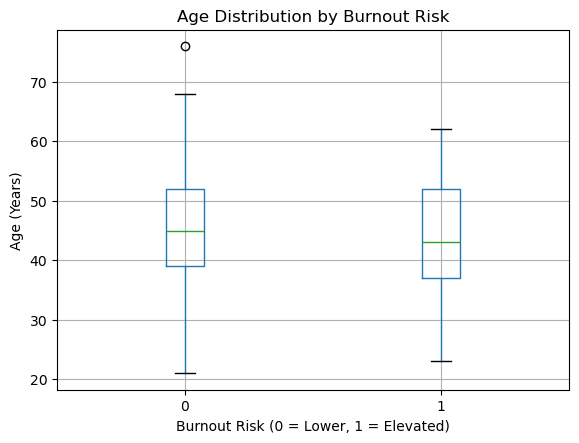

In [61]:
import matplotlib.pyplot as plt

olbi.boxplot(
    column="Age_Calculated",
    by="Burnout_Risk"
)

plt.title("Age Distribution by Burnout Risk")
plt.suptitle("")
plt.xlabel("Burnout Risk (0 = Lower, 1 = Elevated)")
plt.ylabel("Age (Years)")
plt.show()

The age distributions showed substantial overlap between lower- and elevated-burnout-risk groups. The elevated-risk group had a slightly lower median age; however, no substantial visual separation between the groups was observed.

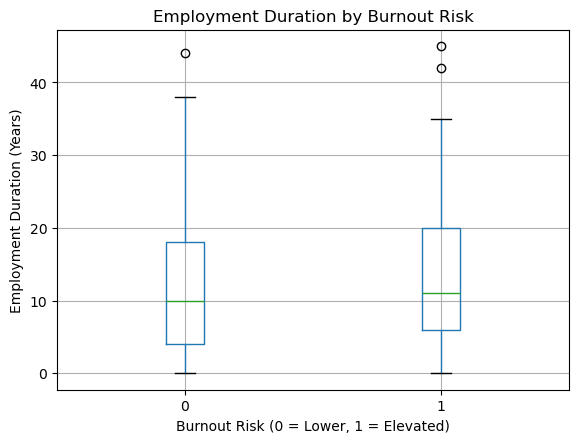

In [62]:
olbi.boxplot(
    column="Employment_Duration",
    by="Burnout_Risk"
)

plt.title("Employment Duration by Burnout Risk")
plt.suptitle("")
plt.xlabel("Burnout Risk (0 = Lower, 1 = Elevated)")
plt.ylabel("Employment Duration (Years)")
plt.show()

Employment duration showed substantial overlap between lower- and elevated-burnout-risk groups. The elevated-risk group had a slightly higher median employment duration; however, no substantial visual separation between the groups was observed.

# Categorical Distribution  

In [63]:
gender_risk = pd.crosstab(
    olbi["Gender"],
    olbi["Burnout_Risk"],
    normalize="index"
) * 100

gender_risk.round(2)

Burnout_Risk,0,1
Gender,,
1.0,75.65,24.35
2.0,69.31,30.69


In [64]:
gender_labels = {
    1.0: "Male",
    2.0: "Female"
}

gender_risk_english = gender_risk.rename(index=gender_labels)
gender_risk_english.round(2)

Burnout_Risk,0,1
Gender,,
Male,75.65,24.35
Female,69.31,30.69


In [65]:
education_labels = {
    1.0: "Basic school education",
    2.0: "High School/Lykeion",
    3.0: "Technical Education",
    4.0: "College/BA/TEI",
    5.0: "College/BA/AEI",
    6.0: "Postgraduate Education"
}

education_risk = pd.crosstab(
    olbi["Education_level"].map(education_labels),
    olbi["Burnout_Risk"],
    normalize="index"
) * 100

education_risk.round(2)

Burnout_Risk,0,1
Education_level,,
Basic school education,63.64,36.36
College/BA/AEI,71.30,28.70
College/BA/TEI,70.48,29.52
High School/Lykeion,73.91,26.09
Postgraduate Education,76.54,23.46
Technical Education,71.93,28.07


Elevated burnout-risk proportions varied across education levels, although differences were relatively modest across most categories. The highest proportion occurred in the Basic School group; however, this category contained very few participants and should therefore be interpreted cautiously.

In [66]:
employment_type_risk = pd.crosstab(
    olbi["Employment_Type_Clean"],
    olbi["Burnout_Risk"],
    normalize="index"
) * 100

employment_type_risk.round(2)

Burnout_Risk,0,1
Employment_Type_Clean,,
Full-time employment,72.6,27.4
Part-time employment,75.0,25.0
Special programme/schedule,62.5,37.5


Burnout-risk proportions were similar for full-time and part-time participants. A higher elevated-risk proportion was observed among participants on special programmes; however, this category contained relatively few observations and should therefore be interpreted cautiously.

In [67]:
sector_risk = pd.crosstab(
    olbi["Sector_Clean"],
    olbi["Burnout_Risk"],
    normalize="index"
) * 100

sector_risk.round(2)

Burnout_Risk,0,1
Sector_Clean,,
Other,100.00,0.00
Private_or_Self_Employed,73.74,26.26
Public,71.34,28.66


Elevated burnout-risk proportions were similar between public-sector and private/self-employed participants. The Other category contained only two observations and was therefore too small for a meaningful interpretation.

# Target Distribution 

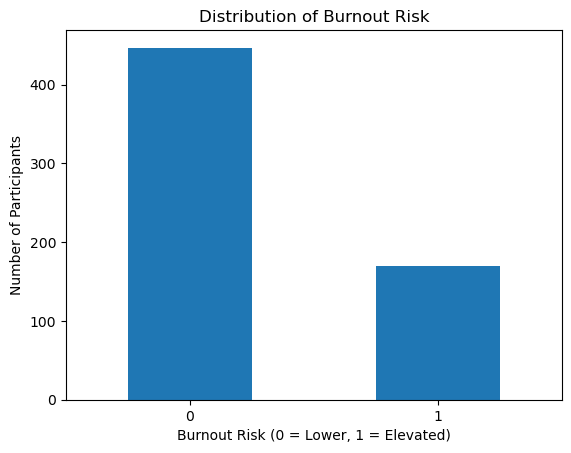

In [68]:
risk_counts = y.value_counts().sort_index()

risk_counts.plot(kind="bar")

plt.title("Distribution of Burnout Risk")
plt.xlabel("Burnout Risk (0 = Lower, 1 = Elevated)")
plt.ylabel("Number of Participants")
plt.xticks(rotation=0)
plt.show()

In [69]:
olbi[
    ["Age_Calculated", "Employment_Duration"]
].corr().round(2)

,Age_Calculated,Employment_Duration
Age_Calculated,1.00,0.45
Employment_Duration,0.45,1.00


The OLBI dataset contains a moderately imbalanced burnout-risk outcome, while the available demographic and employment predictors generally show modest descriptive differences between lower- and elevated-risk participants. No individual predictor demonstrates obvious separation between the risk groups during exploratory analysis.

# Model Preprocessing and Data Preparation

In [70]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTest target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set: (493, 6)
Test set: (124, 6)

Training target percentages:
Burnout_Risk
0    72.41
1    27.59
Name: proportion, dtype: float64

Test target percentages:
Burnout_Risk
0    72.58
1    27.42
Name: proportion, dtype: float64


In [71]:
numeric_features = [
    "Age_Calculated",
    "Employment_Duration"
]

categorical_features = [
    "Gender",
    "Education_level",
    "Employment_Type_Clean",
    "Sector_Clean"
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Age_Calculated', 'Employment_Duration']
Categorical features: ['Gender', 'Education_level', 'Employment_Type_Clean', 'Sector_Clean']


In [72]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_transformer

,steps,"[('imputer', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [73]:
from sklearn.preprocessing import OneHotEncoder

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

categorical_transformer

,steps,"[('imputer', ...), ('onehot', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


In [74]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


# Baseline Logistic Regression Pipeline

In [75]:
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and Logistic Regression into one pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [76]:
# Train the baseline Logistic Regression model using the training data
logistic_model.fit(X_train, y_train)

print("Baseline Logistic Regression model trained successfully.")

Baseline Logistic Regression model trained successfully.


In [77]:
# Predict burnout risk for the unseen test data
y_pred_logistic = logistic_model.predict(X_test)

print("Predictions created:", len(y_pred_logistic))
print("Predicted lower risk (0):", (y_pred_logistic == 0).sum())
print("Predicted elevated risk (1):", (y_pred_logistic == 1).sum())

Predictions created: 124
Predicted lower risk (0): 124
Predicted elevated risk (1): 0


In [78]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Evaluate baseline Logistic Regression predictions
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(y_test, y_pred_logistic, zero_division=0)
recall_logistic = recall_score(y_test, y_pred_logistic, zero_division=0)
f1_logistic = f1_score(y_test, y_pred_logistic, zero_division=0)

print("Confusion Matrix:")
print(cm_logistic)

print("\nAccuracy:", round(accuracy_logistic, 3))
print("Precision:", round(precision_logistic, 3))
print("Recall:", round(recall_logistic, 3))
print("F1-score:", round(f1_logistic, 3))

Confusion Matrix:
[[90  0]
 [34  0]]

Accuracy: 0.726
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [79]:
# Get the predicted probability of elevated burnout risk
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Minimum probability:", round(y_prob_logistic.min(), 3))
print("Maximum probability:", round(y_prob_logistic.max(), 3))
print("Mean probability:", round(y_prob_logistic.mean(), 3))
print("Median probability:", round(float(np.median(y_prob_logistic)), 3))

Minimum probability: 0.128
Maximum probability: 0.423
Mean probability: 0.282
Median probability: 0.271


In [80]:
# Compare predicted probabilities with the participants' actual burnout-risk group
probability_check = pd.DataFrame({
    "Actual_Burnout_Risk": y_test.values,
    "Predicted_Probability": y_prob_logistic
})

probability_check.groupby("Actual_Burnout_Risk")[
    "Predicted_Probability"
].agg(["count", "mean", "median", "min", "max"]).round(3)

,count,mean,median,min,max
Actual_Burnout_Risk,,,,,
0,90,0.277,0.267,0.128,0.423
1,34,0.293,0.275,0.186,0.394


In [81]:
from sklearn.metrics import roc_auc_score

# Evaluate how well the model ranks elevated-risk participants across thresholds
roc_auc_logistic = roc_auc_score(y_test, y_prob_logistic)

print("ROC-AUC:", round(roc_auc_logistic, 3))

ROC-AUC: 0.58


In [82]:
# Store the baseline Logistic Regression results for later model comparison
logistic_baseline_results = {
    "Model": "Logistic Regression - Baseline",
    "Accuracy": accuracy_logistic,
    "Precision": precision_logistic,
    "Recall": recall_logistic,
    "F1": f1_logistic,
    "ROC_AUC": roc_auc_logistic
}

pd.DataFrame([logistic_baseline_results]).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression - Baseline,0.726,0.0,0.0,0.0,0.58


In [83]:
# Give more importance to the minority elevated-risk class during training
logistic_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_balanced

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [84]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Use stratified 5-fold cross-validation on the training data
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

balanced_cv = cross_validate(
    logistic_balanced,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Show the average performance across the five folds
for metric in scoring:
    scores = balanced_cv[f"test_{metric}"]
    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} "
        f"(± {scores.std():.3f})"
    )

Accuracy: 0.546 (± 0.028)
Precision: 0.302 (± 0.021)
Recall: 0.500 (± 0.106)
F1: 0.374 (± 0.040)
Roc_auc: 0.532 (± 0.044)


In [85]:
# Evaluate the baseline model using the same cross-validation procedure
baseline_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Show average performance across the five folds
for metric in scoring:
    scores = baseline_cv[f"test_{metric}"]
    print(
        f"{metric.capitalize()}: "
        f"{scores.mean():.3f} "
        f"(± {scores.std():.3f})"
    )

Accuracy: 0.722 (± 0.004)
Precision: 0.100 (± 0.200)
Recall: 0.007 (± 0.015)
F1: 0.014 (± 0.028)
Roc_auc: 0.538 (± 0.040)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### Logistic Regression Hyperparameter Tuning

Hyperparameter tuning was performed using stratified cross-validation on the
training data. F1-score was used as the primary optimisation metric because the
study aims to identify elevated burnout-risk cases while balancing precision
and recall. The held-out test set was not used during hyperparameter selection.

In [86]:
# Defined a small set of Logistic Regression settings to test
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

In [87]:
from sklearn.model_selection import GridSearchCV

# Search for the best Logistic Regression settings using cross-validation
logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

logistic_grid.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__C': [0.01, 0.1, ...], 'classifier__class_weight': [None, 'balanced']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [88]:
# Shows the best settings found during the tuning
print("Best parameters:", logistic_grid.best_params_)
print("Best cross-validated F1:", round(logistic_grid.best_score_, 3))

Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}
Best cross-validated F1: 0.397


In [89]:
# Use the best Logistic Regression model from the grid search
best_logistic_model = logistic_grid.best_estimator_

# Check how the tuned model performs across the same CV folds
tuned_cv_results = cross_validate(
    best_logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Print the average score for each metric
for metric_name in scoring:
    fold_scores = tuned_cv_results[f"test_{metric_name}"]
    
    avg_score = fold_scores.mean()
    score_spread = fold_scores.std()
    
    print(f"{metric_name.capitalize()}: {avg_score:.3f} (± {score_spread:.3f})")

Accuracy: 0.562 (± 0.024)
Precision: 0.320 (± 0.032)
Recall: 0.529 (± 0.098)
F1: 0.397 (± 0.047)
Roc_auc: 0.557 (± 0.037)


Hyperparameter tuning produced a modest improvement in Logistic Regression performance, particularly for the elevated-risk class. The tuned model achieved higher precision, recall and F1-score than both the baseline and class-weighted models. However, the ROC-AUC of 0.557 indicates that overall discriminatory ability remained limited.

### Final Logistic Regression Model Evaluation

The selected tuned Logistic Regression model was evaluated using the held-out
test dataset. This provides an independent assessment of the model's ability
to classify elevated burnout risk on data that were not used during model
training or hyperparameter tuning.

In [90]:
# Make predictions on the held-out test data
y_pred_tuned = best_logistic_model.predict(X_test)

# Get the predicted probability of elevated burnout risk
y_prob_tuned = best_logistic_model.predict_proba(X_test)[:, 1]

In [91]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

# Calculate the final test scores
final_accuracy = accuracy_score(y_test, y_pred_tuned)
final_precision = precision_score(y_test, y_pred_tuned)
final_recall = recall_score(y_test, y_pred_tuned)
final_f1 = f1_score(y_test, y_pred_tuned)
final_auc = roc_auc_score(y_test, y_prob_tuned)

print(f"Accuracy:  {final_accuracy:.3f}")
print(f"Precision: {final_precision:.3f}")
print(f"Recall:    {final_recall:.3f}")
print(f"F1-score:  {final_f1:.3f}")
print(f"ROC-AUC:   {final_auc:.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Accuracy:  0.556
Precision: 0.316
Recall:    0.529
F1-score:  0.396
ROC-AUC:   0.601

Confusion Matrix:
[[51 39]
 [16 18]]


In [92]:
# Verify the final Logistic Regression results
print("Final Logistic Regression check")
print("--------------------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tuned):.6f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.6f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.6f}")
print(f"F1-score:  {f1_score(y_test, y_pred_tuned):.6f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_tuned):.6f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Final Logistic Regression check
--------------------------------
Accuracy:  0.556452
Precision: 0.315789
Recall:    0.529412
F1-score:  0.395604
ROC-AUC:   0.601307

Confusion Matrix:
[[51 39]
 [16 18]]


### Logistic Regression Model Comparison

In [93]:
# Compare the Logistic Regression models during development
lr_cv_comparison = pd.DataFrame({
    "Baseline": [0.722, 0.100, 0.007, 0.014, 0.538],
    "Balanced": [0.546, 0.302, 0.500, 0.374, 0.532],
    "Tuned": [0.562, 0.320, 0.529, 0.397, 0.557]
}, index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
])

# Show the change between the baseline and tuned model
lr_cv_comparison["Change"] = (
    lr_cv_comparison["Tuned"] - lr_cv_comparison["Baseline"]
)

lr_cv_comparison.round(3)

,Baseline,Balanced,Tuned,Change
Accuracy,0.722,0.546,0.562,-0.160
Precision,0.100,0.302,0.320,0.220
Recall,0.007,0.500,0.529,0.522
F1-score,0.014,0.374,0.397,0.383
ROC-AUC,0.538,0.532,0.557,0.019


### Final Logistic Regression Test Results

The tuned Logistic Regression model was evaluated on the held-out test set after
model selection and hyperparameter tuning were completed. These results represent
the final performance of the Logistic Regression model for the OLBI dataset.

In [94]:
# Final performance on the held-out OLBI test data
lr_final_test = pd.DataFrame({
    "Accuracy": [final_accuracy],
    "Precision": [final_precision],
    "Recall": [final_recall],
    "F1-score": [final_f1],
    "ROC-AUC": [final_auc]
}, index=["Tuned Logistic Regression"])

lr_final_test.round(3)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Tuned Logistic Regression,0.556,0.316,0.529,0.396,0.601


### Logistic Regression Interpretation and Mathematical Analysis

The final Logistic Regression model was examined to understand how the selected
predictor variables contributed to elevated burnout-risk predictions. Model
coefficients and odds ratios were used to assess the direction and relative
influence of each predictor. The mathematical probability calculation was also
examined using the fitted model.

In [95]:
# Get the feature names created during preprocessing
feature_names = best_logistic_model[
    "preprocessor"
].get_feature_names_out()

# Get the coefficients from the tuned Logistic Regression model
lr_coefficients = best_logistic_model[
    "classifier"
].coef_[0]

# Put the feature names and coefficients together
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_coefficients
})

coefficient_table

,Feature,Coefficient
0,num__Age_Calculated,-0.093361
1,num__Employment_Duration,0.101667
2,cat__Gender_1.0,-0.040186
3,cat__Gender_2.0,0.040097
4,cat__Education_level_1.0,0.003713
5,cat__Education_level_2.0,-0.005904
6,cat__Education_level_3.0,-0.003961
7,cat__Education_level_4.0,0.009942
8,cat__Education_level_5.0,-0.004325
9,cat__Education_level_6.0,0.000445


In [96]:
import numpy as np

# Convert the coefficients into odds ratios
coefficient_table["Odds_Ratio"] = np.exp(
    coefficient_table["Coefficient"]
)

# Sort them so the differences are easier to see
coefficient_table = coefficient_table.sort_values(
    by="Odds_Ratio",
    ascending=False
)

coefficient_table.round(3)

,Feature,Coefficient,Odds_Ratio
1,num__Employment_Duration,0.102,1.107
15,cat__Sector_Clean_Public,0.066,1.069
3,cat__Gender_2.0,0.040,1.041
12,cat__Employment_Type_Clean_Special programme/s...,0.017,1.017
7,cat__Education_level_4.0,0.010,1.010
11,cat__Employment_Type_Clean_Part-time employment,0.009,1.009
4,cat__Education_level_1.0,0.004,1.004
9,cat__Education_level_6.0,0.000,1.000
6,cat__Education_level_3.0,-0.004,0.996
8,cat__Education_level_5.0,-0.004,0.996


#### Logistic Regression Probability Calculation

In [97]:
# Get the intercept from the final Logistic Regression model
lr_intercept = best_logistic_model["classifier"].intercept_[0]

print(f"Intercept: {lr_intercept:.4f}")

Intercept: 0.0066


In [98]:
# Find an elevated-risk participant that the model predicted correctly
correct_risk_cases = X_test[
    (y_test == 1) & (y_pred_tuned == 1)
]

example_person = correct_risk_cases.iloc[[0]]

example_person

,Gender,Education_level,Age_Calculated,Employment_Type_Clean,Sector_Clean,Employment_Duration
255,2.0,5.0,52.0,Full-time employment,Private_or_Self_Employed,28.0


In [99]:
# Transform the participant using the same preprocessing as the model
example_transformed = best_logistic_model[
    "preprocessor"
].transform(example_person)

# Put the transformed values next to their feature names
example_values = pd.DataFrame(
    example_transformed.toarray()
    if hasattr(example_transformed, "toarray")
    else example_transformed,
    columns=feature_names
)

example_values.round(3)

,num__Age_Calculated,num__Employment_Duration,cat__Gender_1.0,cat__Gender_2.0,cat__Education_level_1.0,cat__Education_level_2.0,cat__Education_level_3.0,cat__Education_level_4.0,cat__Education_level_5.0,cat__Education_level_6.0,cat__Employment_Type_Clean_Full-time employment,cat__Employment_Type_Clean_Part-time employment,cat__Employment_Type_Clean_Special programme/schedule,cat__Sector_Clean_Other,cat__Sector_Clean_Private_or_Self_Employed,cat__Sector_Clean_Public
0,0.84,1.748,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [100]:
# Calculate how each feature contributes to this prediction
person_values = example_values.iloc[0].values

contributions = person_values * lr_coefficients

math_table = pd.DataFrame({
    "Feature": feature_names,
    "Value": person_values,
    "Coefficient": lr_coefficients,
    "Contribution": contributions
})

# Only show features that were active for this participant
math_table = math_table[math_table["Value"] != 0]

math_table.round(4)

,Feature,Value,Coefficient,Contribution
0,num__Age_Calculated,0.8402,-0.0934,-0.0784
1,num__Employment_Duration,1.7481,0.1017,0.1777
3,cat__Gender_2.0,1.0000,0.0401,0.0401
8,cat__Education_level_5.0,1.0000,-0.0043,-0.0043
10,cat__Employment_Type_Clean_Full-time employment,1.0000,-0.0262,-0.0262
14,cat__Sector_Clean_Private_or_Self_Employed,1.0000,-0.0595,-0.0595


In [101]:
# Recreate the participant's Logistic Regression prediction
z_score = lr_intercept + contributions.sum()
manual_probability = 1 / (1 + np.exp(-z_score))

# Compare it with the probability produced by the model
model_probability = best_logistic_model.predict_proba(example_person)[0, 1]

print(f"Logit score (z): {z_score:.4f}")
print(f"Calculated probability: {manual_probability:.4f}")
print(f"Model probability: {model_probability:.4f}")
print(f"Predicted class: {best_logistic_model.predict(example_person)[0]}")

Logit score (z): 0.0559
Calculated probability: 0.5140
Model probability: 0.5140
Predicted class: 1


#### Logistic Regression Interpretation

The tuned Logistic Regression model demonstrated improved identification of elevated burnout-risk cases compared with the baseline model. On the held-out test set, the final model achieved an accuracy of 55.6%, precision of 31.0%, recall of 52.9%, F1-score of 39.6%, and ROC-AUC of 60.1%. The model correctly identified 18 of the 34 elevated-risk participants in the test set. Although the model demonstrated some ability to distinguish between lower and elevated burnout risk, its overall discriminatory performance remained limited.

The model remained interpretable through its coefficients and odds ratios. Employment duration showed the largest positive numerical coefficient (0.102; OR = 1.107), while age showed a negative coefficient (-0.093; OR = 0.911). As the numerical predictors were standardised, these odds ratios represent changes associated with a one-standard-deviation increase rather than a one-year increase. Most remaining coefficients and odds ratios were relatively close to zero and one respectively, indicating that the available demographic and employment-related predictors had relatively modest influence on the model's predictions. These relationships should be interpreted as model associations rather than causal effects.

Individual predictions could also be traced mathematically. For participant 255, the transformed predictor values and fitted coefficients produced a logit score of 0.0559. Applying the logistic function resulted in a predicted probability of 0.5140 (51.4%) for elevated burnout risk. As this exceeded the model's 0.50 classification threshold, the participant was classified as elevated risk (class 1). The participant's actual outcome was also class 1, making this a true-positive prediction.

Overall, the Logistic Regression model provided a transparent method for examining how the available predictors contributed to burnout-risk classification. However, the relatively modest predictive performance suggests that the limited demographic and employment characteristics available in the OLBI dataset may not provide sufficient information for strong discrimination between lower and elevated burnout risk. This finding will be compared with results from datasets containing richer workplace and psychosocial predictors.

### Logistic Regression Statistical Inference

A separate inferential Logistic Regression analysis was conducted to complement the predictive modelling results. While the primary analysis focused on predictive performance and model interpretability, this analysis was used to examine the statistical evidence associated with individual predictors.

Coefficients, odds ratios, 95% confidence intervals and p-values were estimated. Categorical predictors were dummy-coded using a reference category to avoid perfect multicollinearity. Statistical significance was assessed at p < 0.05; however, significance was interpreted as supplementary evidence and not as a measure of predictive performance or causality.

In [145]:
# Prepare data for inferential Logistic Regression

inferential_data = olbi[
    [
        "Burnout_Risk",
        "Gender",
        "Education_level",
        "Age_Calculated",
        "Employment_Type_Clean",
        "Sector_Clean",
        "Employment_Duration"
    ]
].copy()

# Remove rows with missing values for the inferential analysis
inferential_data = inferential_data.dropna()

print("Inferential sample size:", len(inferential_data))

print("\nOutcome distribution:")
print(inferential_data["Burnout_Risk"].value_counts())

print("\nMissing values:")
print(inferential_data.isnull().sum())

Inferential sample size: 546

Outcome distribution:
Burnout_Risk
0    402
1    144
Name: count, dtype: int64

Missing values:
Burnout_Risk             0
Gender                   0
Education_level          0
Age_Calculated           0
Employment_Type_Clean    0
Sector_Clean             0
Employment_Duration      0
dtype: int64


In [148]:
# Check category sizes and burnout-risk distribution
# before refitting the inferential Logistic Regression

categorical_checks = [
    "Gender",
    "Education_level",
    "Employment_Type_Clean",
    "Sector_Clean"
]

for column in categorical_checks:
    print(f"\n{'='*60}")
    print(column)
    print("="*60)

    print(
        pd.crosstab(
            inferential_data[column],
            inferential_data["Burnout_Risk"],
            margins=True
        )
    )


Gender
Burnout_Risk    0    1  All
Gender                     
1.0           209   60  269
2.0           193   84  277
All           402  144  546

Education_level
Burnout_Risk       0    1  All
Education_level               
1.0                6    3    9
2.0               94   30  124
3.0               34    6   40
4.0               66   30   96
5.0              145   59  204
6.0               57   16   73
All              402  144  546

Employment_Type_Clean
Burnout_Risk                  0    1  All
Employment_Type_Clean                    
Full-time employment        390  138  528
Part-time employment          7    2    9
Special programme/schedule    5    4    9
All                         402  144  546

Sector_Clean
Burnout_Risk                0    1  All
Sector_Clean                           
Other                       2    0    2
Private_or_Self_Employed  176   55  231
Public                    224   89  313
All                       402  144  546


In [149]:
# Prepare predictors for inferential Logistic Regression
# Reference categories are explicitly defined for stable interpretation

X_inferential = inferential_data[
    [
        "Gender",
        "Education_level",
        "Age_Calculated",
        "Employment_Type_Clean",
        "Sector_Clean",
        "Employment_Duration"
    ]
].copy()

y_inferential = inferential_data["Burnout_Risk"]

# Set explicit reference categories
X_inferential["Sector_Clean"] = pd.Categorical(
    X_inferential["Sector_Clean"],
    categories=[
        "Public",
        "Private_or_Self_Employed",
        "Other"
    ]
)

X_inferential["Employment_Type_Clean"] = pd.Categorical(
    X_inferential["Employment_Type_Clean"],
    categories=[
        "Full-time employment",
        "Part-time employment",
        "Special programme/schedule"
    ]
)

# Dummy-code categorical predictors
X_inferential = pd.get_dummies(
    X_inferential,
    columns=[
        "Gender",
        "Education_level",
        "Employment_Type_Clean",
        "Sector_Clean"
    ],
    drop_first=True,
    dtype=float
)

X_inferential = X_inferential.astype(float)

print("Inferential predictor matrix shape:", X_inferential.shape)

print("\nPredictors included:")
for column in X_inferential.columns:
    print("-", column)

Inferential predictor matrix shape: (546, 12)

Predictors included:
- Age_Calculated
- Employment_Duration
- Gender_2.0
- Education_level_2.0
- Education_level_3.0
- Education_level_4.0
- Education_level_5.0
- Education_level_6.0
- Employment_Type_Clean_Part-time employment
- Employment_Type_Clean_Special programme/schedule
- Sector_Clean_Private_or_Self_Employed
- Sector_Clean_Other


#### Sparse Category Handling for Statistical Inference

Prior to inferential Logistic Regression, category frequencies were examined to ensure stable parameter estimation. The `Other` employment-sector category contained only two observations and no elevated-risk cases, resulting in separation and failure of maximum-likelihood estimation to converge.

For the inferential analysis only, this sparse category was therefore combined with the broader non-public sector category. This adjustment was made solely to permit stable statistical estimation and did not alter the predictor structure or results of the primary predictive models.

In [152]:
# Create a separate sector variable for inferential analysis only

inferential_data["Sector_Inference"] = (
    inferential_data["Sector_Clean"]
    .replace({
        "Private_or_Self_Employed": "Non-Public",
        "Other": "Non-Public",
        "Public": "Public"
    })
)

print("Sector distribution used for inference:")
print(
    pd.crosstab(
        inferential_data["Sector_Inference"],
        inferential_data["Burnout_Risk"],
        margins=True
    )
)

Sector distribution used for inference:
Burnout_Risk        0    1  All
Sector_Inference               
Non-Public        178   55  233
Public            224   89  313
All               402  144  546


In [153]:
# Rebuild predictor matrix using the grouped sector variable

X_inferential = inferential_data[
    [
        "Gender",
        "Education_level",
        "Age_Calculated",
        "Employment_Type_Clean",
        "Sector_Inference",
        "Employment_Duration"
    ]
].copy()

y_inferential = inferential_data["Burnout_Risk"]

# Explicit reference categories
X_inferential["Employment_Type_Clean"] = pd.Categorical(
    X_inferential["Employment_Type_Clean"],
    categories=[
        "Full-time employment",
        "Part-time employment",
        "Special programme/schedule"
    ]
)

X_inferential["Sector_Inference"] = pd.Categorical(
    X_inferential["Sector_Inference"],
    categories=[
        "Public",
        "Non-Public"
    ]
)

# Dummy-code categorical variables
X_inferential = pd.get_dummies(
    X_inferential,
    columns=[
        "Gender",
        "Education_level",
        "Employment_Type_Clean",
        "Sector_Inference"
    ],
    drop_first=True,
    dtype=float
)

X_inferential = X_inferential.astype(float)

print("Inferential predictor matrix shape:", X_inferential.shape)

print("\nPredictors included:")
for column in X_inferential.columns:
    print("-", column)

Inferential predictor matrix shape: (546, 11)

Predictors included:
- Age_Calculated
- Employment_Duration
- Gender_2.0
- Education_level_2.0
- Education_level_3.0
- Education_level_4.0
- Education_level_5.0
- Education_level_6.0
- Employment_Type_Clean_Part-time employment
- Employment_Type_Clean_Special programme/schedule
- Sector_Inference_Non-Public


In [154]:
# Fit inferential Logistic Regression

X_inferential_sm = sm.add_constant(X_inferential)

inferential_lr = sm.Logit(
    y_inferential,
    X_inferential_sm
).fit(maxiter=100)

print(inferential_lr.summary())

Optimization terminated successfully.
         Current function value: 0.557663
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           Burnout_Risk   No. Observations:                  546
Model:                          Logit   Df Residuals:                      534
Method:                           MLE   Df Model:                           11
Date:                Wed, 07 Oct 2026   Pseudo R-squ.:                 0.03339
Time:                        12:21:23   Log-Likelihood:                -304.48
converged:                       True   LL-Null:                       -315.00
Covariance Type:            nonrobust   LLR p-value:                   0.03297
                                                       coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------
const                           

In [155]:
# Extract inferential Logistic Regression results

import numpy as np

confidence_intervals = inferential_lr.conf_int()

inference_results = pd.DataFrame({
    "Predictor": inferential_lr.params.index,
    "Coefficient": inferential_lr.params.values,
    "Odds Ratio": np.exp(inferential_lr.params.values),
    "CI Lower": np.exp(confidence_intervals[0].values),
    "CI Upper": np.exp(confidence_intervals[1].values),
    "p-value": inferential_lr.pvalues.values
})

# Remove intercept from interpretation table
inference_results = inference_results[
    inference_results["Predictor"] != "const"
].copy()

# Add significance indicator
inference_results["Significant (p < 0.05)"] = np.where(
    inference_results["p-value"] < 0.05,
    "Yes",
    "No"
)

# Combine confidence interval into one readable column
inference_results["95% CI for OR"] = (
    inference_results["CI Lower"].map("{:.3f}".format)
    + " – "
    + inference_results["CI Upper"].map("{:.3f}".format)
)

# Final table
inference_table = inference_results[
    [
        "Predictor",
        "Coefficient",
        "Odds Ratio",
        "95% CI for OR",
        "p-value",
        "Significant (p < 0.05)"
    ]
]

display(
    inference_table.style
    .format({
        "Coefficient": "{:.3f}",
        "Odds Ratio": "{:.3f}",
        "p-value": "{:.3f}"
    })
    .background_gradient(
        subset=["Odds Ratio"],
        cmap="Blues"
    )
    .set_caption(
        "Inferential Logistic Regression Results for Elevated Burnout Risk"
    )
    .hide(axis="index")
)

Predictor,Coefficient,Odds Ratio,95% CI for OR,p-value,Significant (p < 0.05)
Age_Calculated,-0.037,0.963,0.938 – 0.990,0.007,Yes
Employment_Duration,0.029,1.029,1.004 – 1.055,0.024,Yes
Gender_2.0,0.335,1.398,0.935 – 2.091,0.103,No
Education_level_2.0,-0.520,0.594,0.137 – 2.579,0.487,No
Education_level_3.0,-0.945,0.389,0.075 – 2.021,0.261,No
Education_level_4.0,-0.125,0.882,0.203 – 3.839,0.868,No
Education_level_5.0,-0.275,0.759,0.179 – 3.218,0.709,No
Education_level_6.0,-0.567,0.567,0.124 – 2.606,0.466,No
Employment_Type_Clean_Part-time employment,0.084,1.087,0.214 – 5.526,0.920,No
Employment_Type_Clean_Special programme/schedule,0.963,2.620,0.663 – 10.349,0.169,No


## Decision Tree Model Development

A Decision Tree classifier was developed as a second interpretable machine-learning approach for predicting elevated burnout risk. The model was trained using the same training and held-out test datasets used for Logistic Regression, allowing the performance of the two modelling approaches to be compared consistently.

### Baseline Decision Tree

In [102]:
from sklearn.tree import DecisionTreeClassifier

# Build the baseline Decision Tree using the same preprocessing pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [103]:
# Make predictions using the baseline Decision Tree
y_pred_tree = decision_tree_model.predict(X_test)

# Get the probability of elevated burnout risk
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

In [104]:
# Check the baseline Decision Tree performance
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(y_test, y_pred_tree)
tree_recall = recall_score(y_test, y_pred_tree)
tree_f1 = f1_score(y_test, y_pred_tree)
tree_auc = roc_auc_score(y_test, y_prob_tree)

print(f"Accuracy:  {tree_accuracy:.3f}")
print(f"Precision: {tree_precision:.3f}")
print(f"Recall:    {tree_recall:.3f}")
print(f"F1-score:  {tree_f1:.3f}")
print(f"ROC-AUC:   {tree_auc:.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

Accuracy:  0.532
Precision: 0.184
Recall:    0.206
F1-score:  0.194
ROC-AUC:   0.431

Confusion Matrix:
[[59 31]
 [27  7]]


### Decision Tree Cross-Validation

The baseline Decision Tree was evaluated using stratified cross-validation on the training data. This was used to assess the model's performance and stability across multiple training-validation splits before hyperparameter tuning. The same evaluation metrics used for Logistic Regression were retained to support consistent model comparison.

In [105]:
# Evaluate the baseline Decision Tree using cross-validation
tree_cv_scores = cross_validate(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = tree_cv_scores[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy: 0.558 ± 0.024
precision: 0.212 ± 0.051
recall: 0.244 ± 0.119
f1: 0.222 ± 0.079
roc_auc: 0.462 ± 0.028


### Decision Tree Hyperparameter Tuning

Hyperparameter tuning was conducted using stratified cross-validation on the training data to control tree complexity and improve generalisation. F1-score was retained as the primary optimisation metric to maintain consistency with the Logistic Regression modelling procedure and to balance precision and recall for the elevated burnout-risk class. The held-out test set was excluded from model selection.

In [106]:
# Parameters to test during Decision Tree tuning
tree_param_grid = {
    "classifier__max_depth": [3, 5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

In [107]:
# Find the best Decision Tree settings using training cross-validation
tree_grid = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=tree_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

tree_grid.fit(X_train, y_train)

print("Best parameters:")
print(tree_grid.best_params_)

print(f"\nBest CV F1-score: {tree_grid.best_score_:.3f}")

Best parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Best CV F1-score: 0.391


In [108]:
# Keep the best Decision Tree found during tuning
best_tree_model = tree_grid.best_estimator_

In [109]:
# Evaluate the tuned Decision Tree across the training folds
tuned_tree_cv = cross_validate(
    best_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

for metric in scoring:
    scores = tuned_tree_cv[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy: 0.562 ± 0.016
precision: 0.317 ± 0.018
recall: 0.523 ± 0.131
f1: 0.391 ± 0.046
roc_auc: 0.535 ± 0.066


### Final Decision Tree Model Evaluation

The tuned Decision Tree selected through training cross-validation was evaluated on the held-out test set. The test data were not used during hyperparameter selection and therefore provide an independent evaluation of the final selected model.

In [110]:
# Final predictions on the held-out test set
y_pred_tree_tuned = best_tree_model.predict(X_test)
y_prob_tree_tuned = best_tree_model.predict_proba(X_test)[:, 1]

final_tree_accuracy = accuracy_score(y_test, y_pred_tree_tuned)
final_tree_precision = precision_score(y_test, y_pred_tree_tuned)
final_tree_recall = recall_score(y_test, y_pred_tree_tuned)
final_tree_f1 = f1_score(y_test, y_pred_tree_tuned)
final_tree_auc = roc_auc_score(y_test, y_prob_tree_tuned)

print(f"Accuracy:  {final_tree_accuracy:.3f}")
print(f"Precision: {final_tree_precision:.3f}")
print(f"Recall:    {final_tree_recall:.3f}")
print(f"F1-score:  {final_tree_f1:.3f}")
print(f"ROC-AUC:   {final_tree_auc:.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree_tuned))

Accuracy:  0.508
Precision: 0.271
Recall:    0.471
F1-score:  0.344
ROC-AUC:   0.521

Confusion Matrix:
[[47 43]
 [18 16]]


### Decision Tree Refinement and Pruning

Following the initial hyperparameter search, a second-stage tuning procedure was conducted on the training data to further examine tree complexity and cost-complexity pruning. Model selection remained based on stratified cross-validation and F1-score, without using the held-out test set for parameter selection.

In [111]:
# Refine the Decision Tree and test pruning options
refined_tree_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [6, 8, 10, 12, 15],
    "classifier__min_samples_split": [2, 4, 6, 8],
    "classifier__min_samples_leaf": [3, 5, 7, 10],
    "classifier__class_weight": [None, "balanced"],
    "classifier__ccp_alpha": [0.0, 0.001, 0.005, 0.01]
}

In [112]:
# Run the refined Decision Tree search
refined_tree_search = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=refined_tree_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

refined_tree_search.fit(X_train, y_train)

print("Best refined parameters:")
print(refined_tree_search.best_params_)

print(f"\nBest refined CV F1-score: {refined_tree_search.best_score_:.3f}")

Best refined parameters:
{'classifier__ccp_alpha': 0.0, 'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Best refined CV F1-score: 0.391


In [113]:
print(refined_tree_search.best_params_)

{'classifier__ccp_alpha': 0.0, 'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}


The second-stage tuning procedure did not improve the best cross-validated F1-score beyond 0.391. The refined search selected the same core configuration identified during the initial tuning stage: balanced class weighting, a maximum depth of 10, a minimum leaf size of 5, and a minimum split size of 2. The refined search additionally selected the Gini criterion and no cost-complexity pruning (`ccp_alpha = 0.0`). As broader tuning did not provide further improvement, additional parameter searching was not pursued. This suggests that the Decision Tree's limited predictive performance is more likely related to the information available in the predictor set than insufficient model optimisation.

### Decision Tree Interpretation and Feature Importance

The final Decision Tree was examined to identify the predictors that contributed most strongly to its classification decisions. Feature importance scores were extracted from the fitted tree to provide a global interpretation of the relative contribution of each predictor. Higher importance values indicate that a feature contributed more to reducing impurity across the tree's decision splits.

In [114]:
# Get the feature names and importance scores from the final Decision Tree
tree_feature_names = best_tree_model["preprocessor"].get_feature_names_out()
tree_importance = best_tree_model["classifier"].feature_importances_

tree_importance_table = pd.DataFrame({
    "Feature": tree_feature_names,
    "Importance": tree_importance
}).sort_values("Importance", ascending=False)

tree_importance_table

,Feature,Importance
0,num__Age_Calculated,0.490901
1,num__Employment_Duration,0.281553
8,cat__Education_level_5.0,0.044795
2,cat__Gender_1.0,0.036405
5,cat__Education_level_2.0,0.033475
14,cat__Sector_Clean_Private_or_Self_Employed,0.029306
15,cat__Sector_Clean_Public,0.027006
3,cat__Gender_2.0,0.022454
7,cat__Education_level_4.0,0.021831
9,cat__Education_level_6.0,0.012273


#### Visualisation of the Decision Tree Structure

The upper levels of the final fitted Decision Tree were visualised to illustrate the primary decision rules used by the model. Only the first three levels are displayed for readability; the underlying fitted model retains its full tree structure.

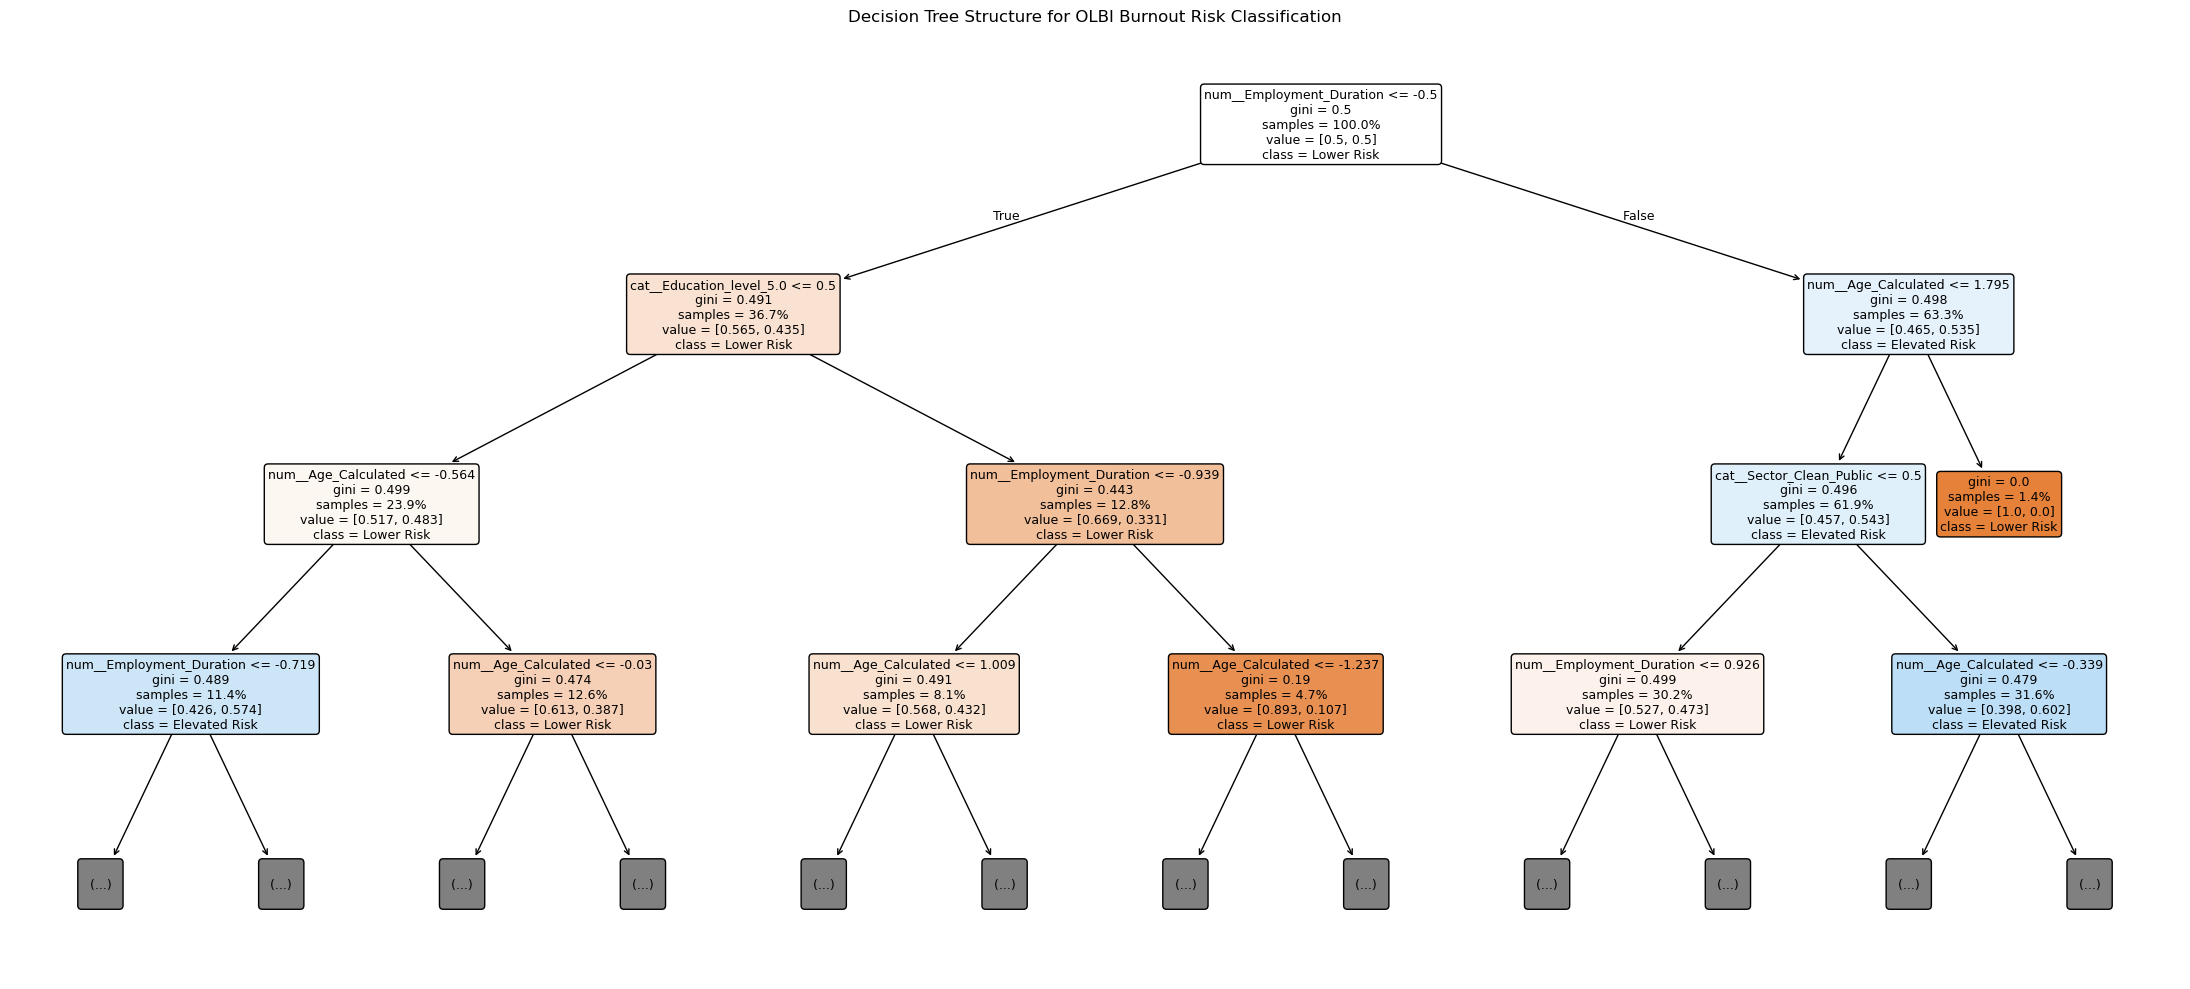

In [115]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Display the main structure of the final Decision Tree
plt.figure(figsize=(22, 10))

plot_tree(
    best_tree_model["classifier"],
    feature_names=tree_feature_names,
    class_names=["Lower Risk", "Elevated Risk"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9,
    proportion=True
)

plt.title("Decision Tree Structure for OLBI Burnout Risk Classification")
plt.tight_layout()
plt.show()

### Decision Tree Refit for Improved Interpretability

Following visualisation of the initial fitted Decision Tree, the numerical split thresholds were displayed as standardised values because the original preprocessing pipeline included feature scaling. Although this did not prevent the Decision Tree from functioning correctly, standardisation is not required for tree-based models and made the resulting decision rules less intuitive to interpret.

The Decision Tree was therefore refitted using model-specific preprocessing in which numerical predictors were median-imputed but retained in their original units. This allows decision thresholds for variables such as age and employment duration to be presented directly in years, improving the transparency and interpretability of the final tree. The same predictors, outcome variable, training and test split, cross-validation procedure, tuning approach and evaluation metrics were retained.

In [116]:
# Numerical preprocessing for the Decision Tree
tree_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [117]:
# Combine Decision Tree preprocessing
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", tree_numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [118]:
# Build the Decision Tree 
decision_tree_model = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

In [119]:
# Tune the refitted Decision Tree using training data only
tree_refit_search = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=refined_tree_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

tree_refit_search.fit(X_train, y_train)

print("Best parameters:")
print(tree_refit_search.best_params_)

print(f"\nBest CV F1-score: {tree_refit_search.best_score_:.3f}")

Best parameters:
{'classifier__ccp_alpha': 0.0, 'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Best CV F1-score: 0.392


In [120]:
best_tree_model = tree_refit_search.best_estimator_

In [121]:
# Final evaluation of the refitted Decision Tree
y_pred_tree_tuned = best_tree_model.predict(X_test)
y_prob_tree_tuned = best_tree_model.predict_proba(X_test)[:, 1]

final_tree_accuracy = accuracy_score(y_test, y_pred_tree_tuned)
final_tree_precision = precision_score(y_test, y_pred_tree_tuned)
final_tree_recall = recall_score(y_test, y_pred_tree_tuned)
final_tree_f1 = f1_score(y_test, y_pred_tree_tuned)
final_tree_auc = roc_auc_score(y_test, y_prob_tree_tuned)

print(f"Accuracy:  {final_tree_accuracy:.3f}")
print(f"Precision: {final_tree_precision:.3f}")
print(f"Recall:    {final_tree_recall:.3f}")
print(f"F1-score:  {final_tree_f1:.3f}")
print(f"ROC-AUC:   {final_tree_auc:.3f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree_tuned))

Accuracy:  0.508
Precision: 0.271
Recall:    0.471
F1-score:  0.344
ROC-AUC:   0.521

Confusion Matrix:
[[47 43]
 [18 16]]


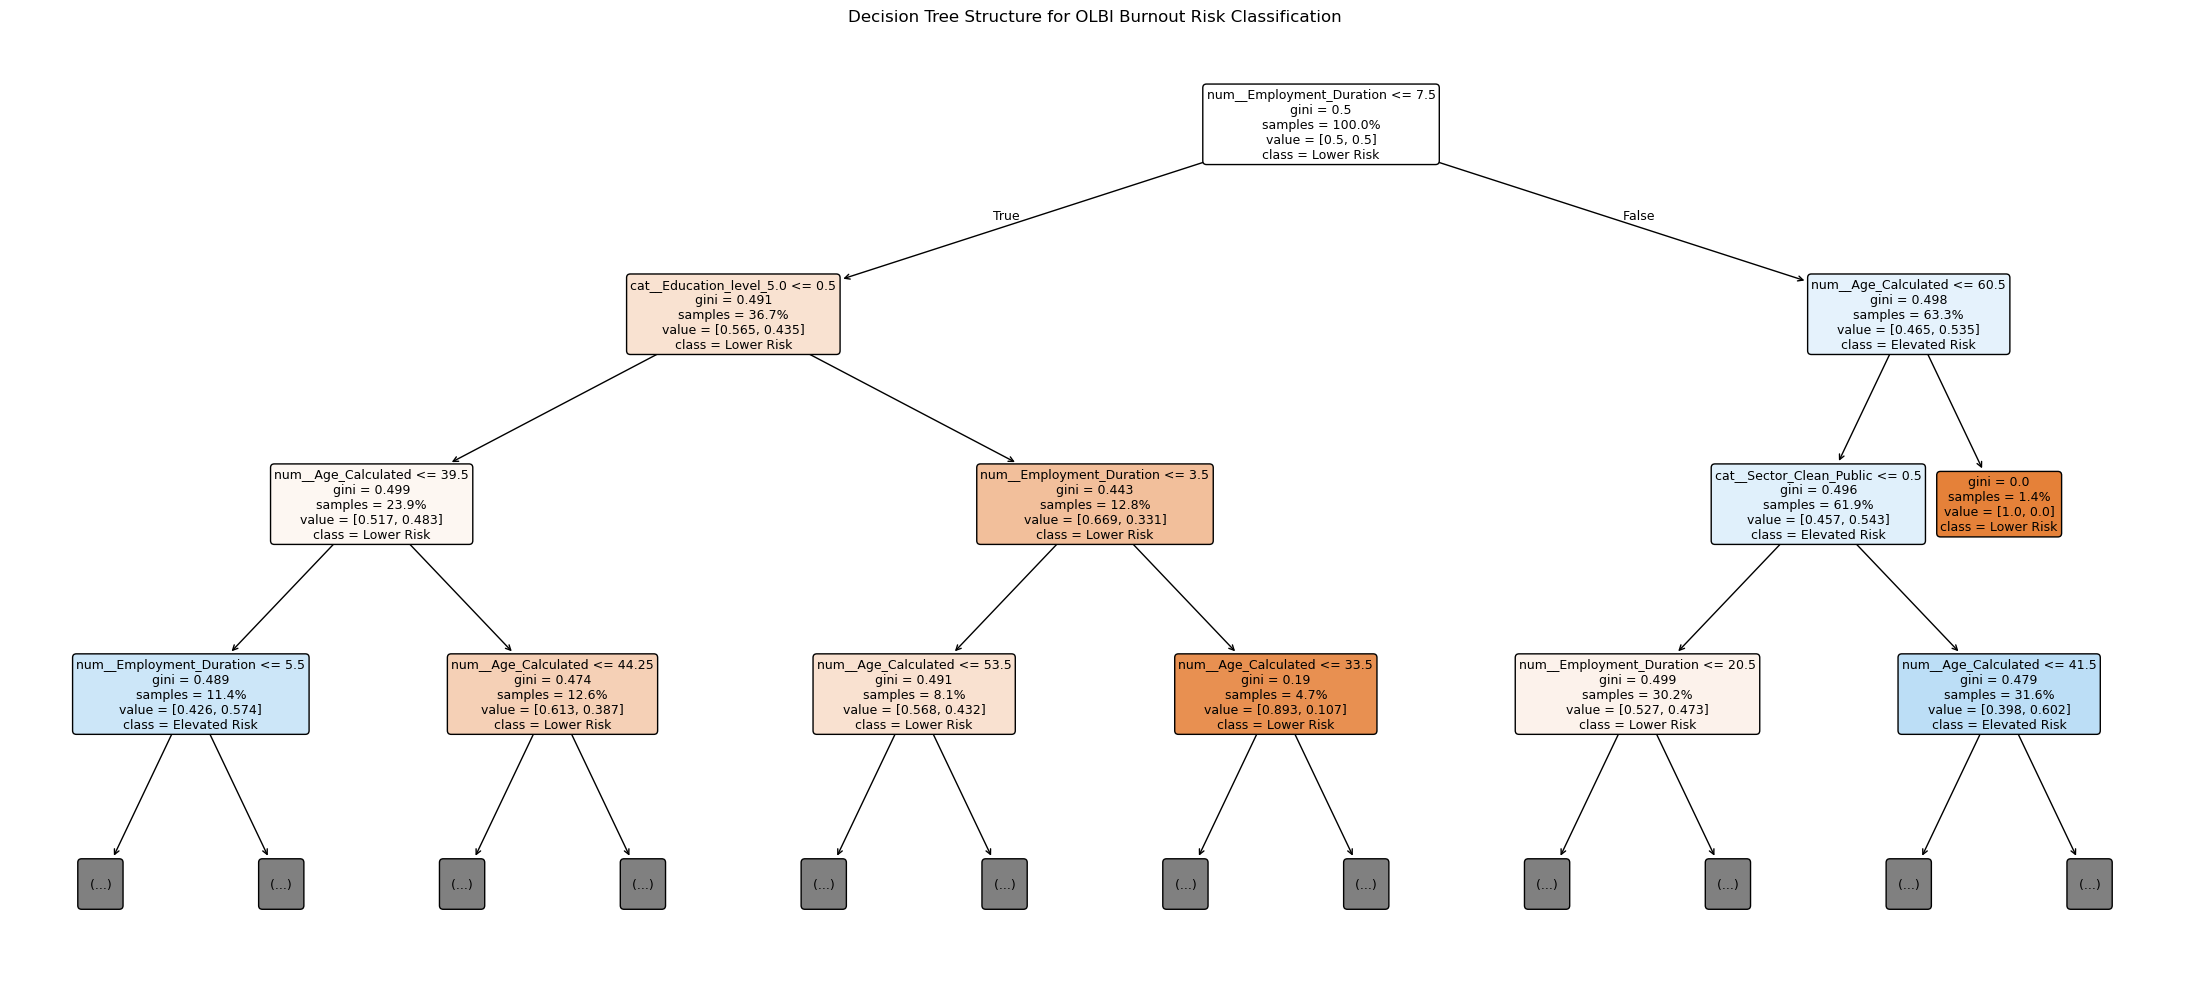

In [122]:
# Get feature names from the final refitted Decision Tree
tree_feature_names = best_tree_model["preprocessor"].get_feature_names_out()

plt.figure(figsize=(22, 10))

plot_tree(
    best_tree_model["classifier"],
    feature_names=tree_feature_names,
    class_names=["Lower Risk", "Elevated Risk"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9,
    proportion=True
)

plt.title("Decision Tree Structure for OLBI Burnout Risk Classification")
plt.tight_layout()
plt.show()

In [123]:
# Feature importance for the final refitted Decision Tree
tree_feature_names = best_tree_model["preprocessor"].get_feature_names_out()
tree_importance = best_tree_model["classifier"].feature_importances_

tree_importance_table = pd.DataFrame({
    "Feature": tree_feature_names,
    "Importance": tree_importance
}).sort_values("Importance", ascending=False)

tree_importance_table

,Feature,Importance
0,num__Age_Calculated,0.490901
1,num__Employment_Duration,0.281553
8,cat__Education_level_5.0,0.044795
2,cat__Gender_1.0,0.036405
5,cat__Education_level_2.0,0.033475
14,cat__Sector_Clean_Private_or_Self_Employed,0.029306
15,cat__Sector_Clean_Public,0.027006
3,cat__Gender_2.0,0.022454
7,cat__Education_level_4.0,0.021831
9,cat__Education_level_6.0,0.012273


#### Decision Tree Interpretation

The final Decision Tree relied predominantly on age and employment duration when classifying elevated burnout risk. Age had the highest overall feature importance (0.491), accounting for approximately 49.1% of the total importance, followed by employment duration (0.282), which accounted for approximately 28.2%. Together, these two numerical predictors represented approximately 77.3% of the model's total feature importance. Education level, gender and employment sector contributed comparatively smaller amounts, while several categories of employment type and education made no measurable contribution to impurity reduction in the fitted tree.

The visualised tree structure provides further insight into how these predictors were used. Employment duration formed the root split at 7.5 years, indicating that this variable provided the first division of participants within the fitted tree. Age was subsequently used repeatedly across several branches, including thresholds at 39.5 and 60.5 years. This explains why age accumulated the greatest overall feature importance despite employment duration forming the initial split.

These findings indicate which variables were most influential within the fitted Decision Tree rather than establishing causal relationships with burnout risk. The interpretation should also be considered alongside the model's limited predictive performance (F1 = 0.344; ROC-AUC = 0.521), as high relative importance within a weakly discriminating model does not necessarily indicate strong predictive relationships.

### Decision Tree Mathematical Interpretation

Gini impurity was examined to demonstrate mathematically how the Decision Tree evaluates the purity of its nodes when constructing classification rules. A value of 0 represents a completely pure node containing one class, while higher values indicate greater class mixture. The root node of the final fitted Decision Tree was used as an illustrative example.

In [124]:
# Get the final fitted tree
final_tree = best_tree_model["classifier"].tree_

# Root node information
root_values = final_tree.value[0][0]
root_gini = final_tree.impurity[0]
root_samples = final_tree.n_node_samples[0]

print("Root node class values:", root_values)
print("Root node samples:", root_samples)
print(f"Root node Gini impurity: {root_gini:.4f}")

Root node class values: [0.5 0.5]
Root node samples: 493
Root node Gini impurity: 0.5000


#### Root Node Gini Impurity Calculation

The final Decision Tree used balanced class weighting, resulting in weighted class proportions of 0.50 for lower burnout risk and 0.50 for elevated burnout risk at the root node.

Gini impurity is calculated as:

\[
Gini = 1 - \sum_{k=1}^{K} p_k^2
\]

For the two burnout-risk classes at the root node:

\[
Gini = 1 - (0.50^2 + 0.50^2)
\]

\[
Gini = 1 - (0.25 + 0.25)
\]

\[
Gini = 0.50
\]

The calculated Gini impurity of 0.50 matches the value produced by the fitted Decision Tree. This represents a highly mixed binary node, meaning that the root node does not initially separate lower and elevated burnout-risk cases. The tree therefore searches for predictor thresholds that reduce impurity in the resulting child nodes.

In [125]:
# Manually calculate Gini impurity at the root node
p_lower = root_values[0]
p_elevated = root_values[1]

manual_gini = 1 - (p_lower**2 + p_elevated**2)

print(f"Manual Gini calculation: {manual_gini:.4f}")
print(f"Model Gini impurity:     {root_gini:.4f}")

Manual Gini calculation: 0.5000
Model Gini impurity:     0.5000


In [126]:
# Get the two child nodes created by the root split
left_node = final_tree.children_left[0]
right_node = final_tree.children_right[0]

left_values = final_tree.value[left_node][0]
right_values = final_tree.value[right_node][0]

left_gini = final_tree.impurity[left_node]
right_gini = final_tree.impurity[right_node]

left_samples = final_tree.n_node_samples[left_node]
right_samples = final_tree.n_node_samples[right_node]

print("LEFT: Employment Duration <= 7.5 years")
print("Samples:", left_samples)
print("Class values:", left_values)
print(f"Gini: {left_gini:.4f}")

print("\nRIGHT: Employment Duration > 7.5 years")
print("Samples:", right_samples)
print("Class values:", right_values)
print(f"Gini: {right_gini:.4f}")

LEFT: Employment Duration <= 7.5 years
Samples: 181
Class values: [0.56537102 0.43462898]
Gini: 0.4915

RIGHT: Employment Duration > 7.5 years
Samples: 312
Class values: [0.46529081 0.53470919]
Gini: 0.4976


In [127]:
# Get the weighted sample sizes used by the fitted tree
root_weight = final_tree.weighted_n_node_samples[0]
left_weight = final_tree.weighted_n_node_samples[left_node]
right_weight = final_tree.weighted_n_node_samples[right_node]

# Calculate weighted Gini after the first split
weighted_gini = (
    (left_weight / root_weight) * left_gini
    + (right_weight / root_weight) * right_gini
)

gini_reduction = root_gini - weighted_gini

print(f"Gini before split:       {root_gini:.4f}")
print(f"Weighted Gini after:     {weighted_gini:.4f}")
print(f"Gini impurity reduction: {gini_reduction:.4f}")

Gini before split:       0.5000
Weighted Gini after:     0.4955
Gini impurity reduction: 0.0045


#### Interpretation of the Root Split

The root node initially had a Gini impurity of 0.5000. The Decision Tree selected employment duration at a threshold of 7.5 years as its first split. Participants with employment duration of 7.5 years or less were directed to the left branch, while those with employment duration greater than 7.5 years were directed to the right branch.

After accounting for the balanced class weights used by the model, the weighted Gini impurity following the split was 0.4955. This represents an impurity reduction of 0.0045 from the original root node. Therefore, employment duration provided some improvement in separating lower and elevated burnout-risk cases, although the reduction in impurity was relatively small.

The small impurity reduction is consistent with the limited discriminatory performance of the final Decision Tree (ROC-AUC = 0.521). Although employment duration was selected as the first decision rule and age contributed strongly across subsequent splits, the available predictors did not produce strong separation between the two burnout-risk classes.

## Final Model Comparison

In [128]:
# Compare the final models on the held-out test set
model_comparison = pd.DataFrame({
    "Logistic Regression": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_auc
    ],
    "Decision Tree": [
        final_tree_accuracy,
        final_tree_precision,
        final_tree_recall,
        final_tree_f1,
        final_tree_auc
    ]
}, index=[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
])

model_comparison.round(3)

,Logistic Regression,Decision Tree
Accuracy,0.556,0.508
Precision,0.316,0.271
Recall,0.529,0.471
F1-score,0.396,0.344
ROC-AUC,0.601,0.521


### Final Model Comparison Interpretation

Logistic Regression demonstrated stronger held-out performance than the Decision Tree across all five evaluation metrics. Logistic Regression achieved an accuracy of 55.6%, precision of 31.0%, recall of 52.9%, F1-score of 39.6%, and ROC-AUC of 60.1%. In comparison, the Decision Tree achieved an accuracy of 50.8%, precision of 27.1%, recall of 47.1%, F1-score of 34.4%, and ROC-AUC of 52.1%.

Logistic Regression therefore provided the stronger overall predictive performance for the OLBI dataset. In particular, it identified 18 of the 34 elevated-risk participants in the held-out test set, compared with 16 identified by the Decision Tree. However, neither model demonstrated strong discrimination between lower and elevated burnout-risk participants. The relatively modest performance of both models suggests that the limited demographic and employment-related predictors available in the OLBI dataset provided only weak predictive information for burnout-risk classification.

From an interpretability perspective, the two models provided complementary explanations. Logistic Regression quantified the direction and magnitude of associations through coefficients and odds ratios and allowed individual predictions to be traced mathematically from predictor values to predicted probabilities. The Decision Tree provided explicit decision rules and feature-importance scores, showing that age and employment duration were the variables most frequently used to reduce impurity. Together, the models demonstrate how interpretable machine-learning approaches can provide transparent explanations even where predictive performance is limited.

## Exploratory Data Analysis and Results Visualisation

The following visualisations summarise the distribution of burnout risk, the relationships between key predictors and burnout risk, and the performance and interpretability of the final machine-learning models. These figures were produced to support the interpretation and reporting of the OLBI dataset results.

### Distribution of the Harmonised Burnout Score

The distribution of the Harmonised Burnout Score (HBS) was examined to describe burnout-risk scores within the OLBI dataset. The 75th-percentile threshold used to define elevated burnout risk is displayed to illustrate how the binary classification outcome was derived.

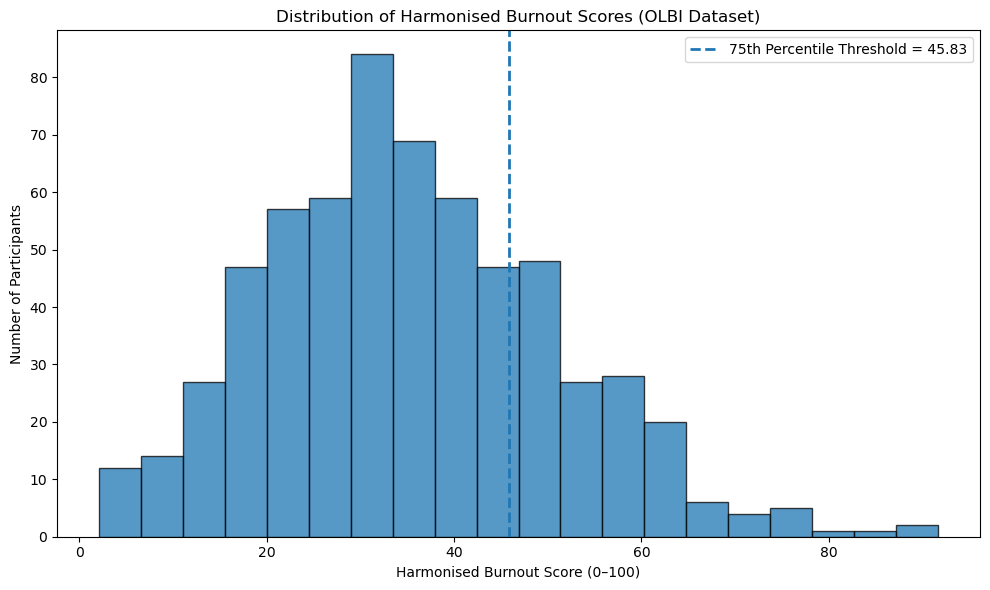

In [129]:
# Visualise the distribution of the Harmonised Burnout Score
plt.figure(figsize=(10, 6))

plt.hist(
    olbi["HBS"],
    bins=20,
    edgecolor="black",
    alpha=0.75
)

# Show the threshold used to define elevated burnout risk
plt.axvline(
    hbs_threshold,
    linestyle="--",
    linewidth=2,
    label=f"75th Percentile Threshold = {hbs_threshold:.2f}"
)

plt.xlabel("Harmonised Burnout Score (0–100)")
plt.ylabel("Number of Participants")
plt.title("Distribution of Harmonised Burnout Scores (OLBI Dataset)")

plt.legend()
plt.tight_layout()
plt.show()

#### HBS Distribution Interpretation

The Harmonised Burnout Score (HBS) distribution shows that most participants were concentrated within the lower-to-middle portion of the 0–100 scale, with scores most frequently occurring around the 30–40 range. A smaller number of participants displayed substantially higher burnout scores, producing a visible upper tail in the distribution.

The 75th-percentile threshold of 45.83 was used to distinguish elevated from lower burnout risk. Participants with an HBS of 45.83 or above were classified as elevated burnout risk (class 1), while participants below this threshold were classified as lower burnout risk (class 0). The threshold represents a dataset-relative screening definition used for the machine-learning classification task and should not be interpreted as a clinical diagnostic cut-off.

### Burnout Risk Class Distribution

The distribution of the binary burnout-risk outcome was examined to assess the balance between lower and elevated burnout-risk participants prior to model development.

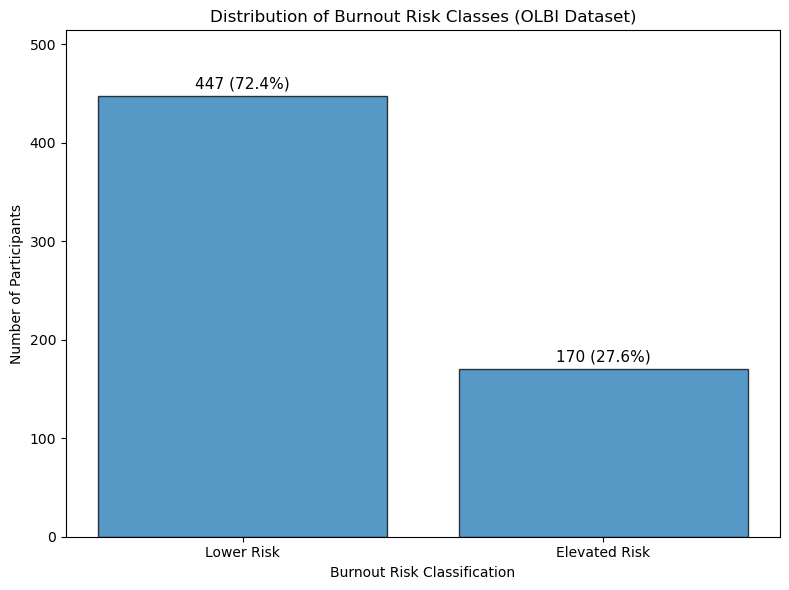

In [130]:
# Count participants in each burnout-risk group
risk_counts = olbi["Burnout_Risk"].value_counts().sort_index()
risk_percentages = risk_counts / len(olbi) * 100

risk_labels = ["Lower Risk", "Elevated Risk"]

plt.figure(figsize=(8, 6))

bars = plt.bar(
    risk_labels,
    risk_counts,
    edgecolor="black",
    alpha=0.75
)

# Add count and percentage above each bar
for bar, count, percentage in zip(bars, risk_counts, risk_percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 8,
        f"{count} ({percentage:.1f}%)",
        ha="center",
        fontsize=11
    )

plt.xlabel("Burnout Risk Classification")
plt.ylabel("Number of Participants")
plt.title("Distribution of Burnout Risk Classes (OLBI Dataset)")
plt.ylim(0, max(risk_counts) * 1.15)

plt.tight_layout()
plt.show()

#### Burnout Risk Class Distribution Interpretation

The binary burnout-risk outcome contained 447 participants (72.4%) classified as lower risk and 170 participants (27.6%) classified as elevated risk. This indicates a moderate class imbalance, with lower-risk participants representing the majority class.

The imbalance was considered during model development because accuracy alone could provide a misleading indication of predictive performance. For example, a model predominantly predicting the majority class could achieve relatively high accuracy while failing to identify elevated-risk participants. Precision, recall, F1-score and ROC-AUC were therefore considered alongside accuracy, while balanced class weighting was evaluated during model optimisation.

### Age Distribution by Burnout Risk

Age distributions were compared between lower and elevated burnout-risk participants to examine whether differences were visible between the two outcome groups. Age was subsequently identified as an influential predictor within the interpretable models.

In [131]:
import plotly.express as px

In [132]:
#  age distribution by burnout-risk group
age_plot = olbi[
    ["Age_Calculated", "Burnout_Risk", "HBS"]
].dropna().copy()

age_plot["Risk Group"] = age_plot["Burnout_Risk"].map({
    0: "Lower Risk",
    1: "Elevated Risk"
})

fig = px.box(
    age_plot,
    x="Risk Group",
    y="Age_Calculated",
    points="all",
    hover_data={
        "HBS": ":.2f",
        "Burnout_Risk": False,
        "Risk Group": False
    },
    labels={
        "Risk Group": "Burnout Risk Classification",
        "Age_Calculated": "Age (Years)",
        "HBS": "Harmonised Burnout Score"
    },
    title="Age Distribution by Burnout Risk (OLBI Dataset)"
)

fig.update_traces(
    jitter=0.35,
    pointpos=0,
    marker=dict(size=5, opacity=0.45)
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    hovermode="closest",
    showlegend=False
)

fig.show()

#### Age Distribution Interpretation

The age distributions of the lower and elevated burnout-risk groups showed substantial overlap, indicating that age alone did not clearly separate the two risk classes. The lower-risk group had a median age of approximately 45 years, while the elevated-risk group showed a slightly lower central age distribution.

Despite this overlap, age became an influential variable within the fitted interpretable models and accounted for approximately 49.1% of the final Decision Tree's total feature importance. This indicates that the tree repeatedly used age when constructing decision rules, rather than suggesting that age independently provides strong discrimination between burnout-risk groups. The relationship should therefore be interpreted within the multivariable model and not as evidence of a causal effect.

### Employment Duration by Burnout Risk

Employment duration was compared between lower and elevated burnout-risk participants to examine differences in occupational tenure between the two groups. Employment duration was subsequently identified as one of the most influential predictors within both interpretable modelling approaches.

In [133]:
# employment-duration distribution by burnout-risk group
duration_plot = olbi[
    ["Employment_Duration", "Burnout_Risk", "HBS"]
].dropna().copy()

duration_plot["Risk Group"] = duration_plot["Burnout_Risk"].map({
    0: "Lower Risk",
    1: "Elevated Risk"
})

fig = px.box(
    duration_plot,
    x="Risk Group",
    y="Employment_Duration",
    points="all",
    hover_data={
        "HBS": ":.2f",
        "Burnout_Risk": False,
        "Risk Group": False
    },
    labels={
        "Risk Group": "Burnout Risk Classification",
        "Employment_Duration": "Employment Duration (Years)",
        "HBS": "Harmonised Burnout Score"
    },
    title="Employment Duration by Burnout Risk (OLBI Dataset)"
)

fig.update_traces(
    jitter=0.35,
    pointpos=0,
    marker=dict(size=5, opacity=0.45)
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    hovermode="closest",
    showlegend=False
)

fig.show()

#### Employment Duration Interpretation

Employment duration showed substantial overlap between the lower and elevated burnout-risk groups. The elevated-risk group had a median employment duration of approximately 11 years, compared with approximately 10 years for the lower-risk group, indicating only a modest descriptive difference between the two groups.

Despite the considerable overlap, employment duration was influential within both fitted interpretable models. Logistic Regression produced a positive coefficient for employment duration, while the Decision Tree assigned approximately 28.2% of its total feature importance to this variable and selected employment duration at 7.5 years as its root decision split.

These findings indicate that employment duration contributed to the multivariable classification process but did not independently provide strong separation between burnout-risk groups. The relationship should therefore be interpreted as a model-based association rather than evidence of a causal relationship with burnout.

## Interpretable Model Visualisations

The final fitted models were visualised to support transparent interpretation of their classification behaviour. Logistic Regression was examined through its fitted coefficients and odds ratios, while the Decision Tree was examined through feature importance and explicit decision rules.

### Logistic Regression Odds Ratio Interpretation

In [134]:
# labels for the Logistic Regression features
lr_plot = coefficient_table.copy()

lr_plot["Odds Ratio"] = np.exp(lr_plot["Coefficient"])

feature_labels = {
    "num__Age_Calculated": "Age",
    "num__Employment_Duration": "Employment Duration",
    "cat__Gender_1.0": "Gender: Male",
    "cat__Gender_2.0": "Gender: Female",
    "cat__Education_level_1.0": "Education Level 1",
    "cat__Education_level_2.0": "Education Level 2",
    "cat__Education_level_3.0": "Education Level 3",
    "cat__Education_level_4.0": "Education Level 4",
    "cat__Education_level_5.0": "Education Level 5",
    "cat__Education_level_6.0": "Education Level 6",
    "cat__Employment_Type_Clean_Full-time employment": "Full-time Employment",
    "cat__Employment_Type_Clean_Part-time employment": "Part-time Employment",
    "cat__Employment_Type_Clean_Special programme/schedule": "Special Programme/Schedule",
    "cat__Sector_Clean_Other": "Sector: Other",
    "cat__Sector_Clean_Private_or_Self_Employed": "Sector: Private/Self-employed",
    "cat__Sector_Clean_Public": "Sector: Public"
}

lr_plot["Feature"] = lr_plot["Feature"].replace(feature_labels)

lr_plot = lr_plot.sort_values("Odds Ratio")

In [135]:
# Logistic Regression odds-ratio plot
fig = px.scatter(
    lr_plot,
    x="Odds Ratio",
    y="Feature",
    custom_data=["Coefficient"],
    labels={
        "Odds Ratio": "Odds Ratio",
        "Feature": "Predictor"
    },
    title="Logistic Regression Predictor Effects (OLBI Dataset)"
)

# Reference line: OR = 1 represents no change in modeled odds
fig.add_vline(
    x=1,
    line_dash="dash",
    annotation_text="OR = 1",
    annotation_position="top"
)

# Clean marker and hover appearance
fig.update_traces(
    marker=dict(size=10, opacity=0.8),
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Odds Ratio: %{x:.3f}<br>"
        "Coefficient: %{customdata[0]:.4f}"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=650,
    showlegend=False
)

fig.show()

#### Logistic Regression Odds Ratio Interpretation

The odds-ratio visualisation provides a view of the direction and relative magnitude of the predictor effects within the final Logistic Regression model. An odds ratio above 1 indicates an association with increased modelled odds of elevated burnout risk, while an odds ratio below 1 indicates an association with decreased modelled odds. Values close to 1 indicate relatively small effects within the fitted model.

Employment duration showed the largest positive numerical effect (OR = 1.107), while age showed the largest negative numerical effect (OR = 0.911). As these numerical predictors were standardised before Logistic Regression modelling, their odds ratios represent approximately a one-standard-deviation increase rather than a one-year increase.

Most predictor odds ratios were concentrated close to 1, indicating relatively modest effects. This is consistent with the limited overall discriminatory performance of the Logistic Regression model (ROC-AUC = 0.601). The categorical coefficients should be interpreted cautiously because all one-hot encoded categories were retained rather than estimated against a single omitted reference category. Overall, the visualisation demonstrates how the Logistic Regression model can be inspected transparently while avoiding causal interpretation of the fitted associations.

### Decision Tree Feature Importance

In [136]:
# Decision Tree feature names
tree_plot = tree_importance_table.copy()

tree_plot["Feature"] = tree_plot["Feature"].replace({
    "num__Age_Calculated": "Age",
    "num__Employment_Duration": "Employment Duration",
    "cat__Gender_1.0": "Gender: Male",
    "cat__Gender_2.0": "Gender: Female",
    "cat__Education_level_1.0": "Education Level 1",
    "cat__Education_level_2.0": "Education Level 2",
    "cat__Education_level_3.0": "Education Level 3",
    "cat__Education_level_4.0": "Education Level 4",
    "cat__Education_level_5.0": "Education Level 5",
    "cat__Education_level_6.0": "Education Level 6",
    "cat__Employment_Type_Clean_Full-time employment": "Full-time Employment",
    "cat__Employment_Type_Clean_Part-time employment": "Part-time Employment",
    "cat__Employment_Type_Clean_Special programme/schedule": "Special Programme/Schedule",
    "cat__Sector_Clean_Other": "Sector: Other",
    "cat__Sector_Clean_Private_or_Self_Employed": "Sector: Private/Self-employed",
    "cat__Sector_Clean_Public": "Sector: Public"
})

In [137]:
# Decision Tree feature-importance visualisation
fig = px.bar(
    tree_plot.sort_values("Importance"),
    x="Importance",
    y="Feature",
    orientation="h",
    labels={
        "Importance": "Feature Importance",
        "Feature": "Predictor"
    },
    title="Decision Tree Feature Importance (OLBI Dataset)"
)

fig.update_traces(
    hovertemplate=(
        "<b>%{y}</b><br>"
        "Feature Importance: %{x:.3f}"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    height=650,
    showlegend=False
)

fig.show()

#### Decision Tree Feature Importance Interpretation

The Decision Tree feature-importance analysis shows that age and employment duration were the dominant predictors used by the fitted model. Age accounted for approximately 49.1% of the total feature importance, followed by employment duration at approximately 28.2%. Together, these variables represented approximately 77.3% of the model's total feature importance.

The remaining predictors contributed substantially less to impurity reduction. Education level, gender and employment sector provided smaller contributions, while several education and employment-type categories had an importance of zero, indicating that they were not used to reduce impurity within the fitted tree.

These results complement the visual tree structure, where employment duration formed the root split at 7.5 years and age appeared repeatedly across subsequent decision rules. Feature importance represents the relative contribution of predictors within this fitted model and should not be interpreted as evidence that age or employment duration causes elevated burnout risk. The findings should also be considered alongside the Decision Tree's limited predictive performance (ROC-AUC = 0.521).

### Final Model Performance Comparison

In [138]:
# model results for visualisation
performance_plot = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall",
        "F1-score", "ROC-AUC"
    ],
    "Logistic Regression": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        final_auc
    ],
    "Decision Tree": [
        final_tree_accuracy,
        final_tree_precision,
        final_tree_recall,
        final_tree_f1,
        final_tree_auc
    ]
})

performance_long = performance_plot.melt(
    id_vars="Metric",
    var_name="Model",
    value_name="Score"
)

In [139]:
fig = px.bar(
    performance_long,
    x="Metric",
    y="Score",
    color="Model",
    barmode="group",
    text="Score",
    title="Final Held-Out Model Performance (OLBI Dataset)",
    labels={
        "Score": "Performance Score",
        "Metric": "Evaluation Metric"
    },
    color_discrete_map={
        "Logistic Regression": "#4C78A8",
        "Decision Tree": "#72B7B2"
    }
)

fig.update_traces(
    texttemplate="%{text:.3f}",
    textposition="outside",
    hovertemplate=(
        "<b>%{fullData.name}</b><br>"
        "%{x}: %{y:.3f}"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    yaxis_range=[0, 0.7],
    legend_title_text="Model"
)

fig.show()

#### Final Model Performance Interpretation

Logistic Regression achieved stronger held-out performance than the Decision Tree across all five evaluation metrics. It produced higher accuracy, precision, recall, F1-score and ROC-AUC, with the largest difference observed in ROC-AUC (0.601 compared with 0.521 for the Decision Tree).

Logistic Regression therefore provided the stronger overall classification performance for the OLBI dataset. However, its ROC-AUC of 0.601 still indicates limited discrimination between lower and elevated burnout-risk participants. The Decision Tree demonstrated weaker discrimination, with a ROC-AUC of 0.521, which is close to chance-level ranking performance.

The results therefore suggest that the limited demographic and employment-related predictors available in the OLBI dataset constrained predictive performance. Nevertheless, both models remained transparent and allowed their prediction mechanisms and influential variables to be directly examined.

### Confusion Matrix Analysis

Confusion matrices were examined to provide a direct comparison of correct and incorrect classifications produced by the final models on the held-out test set.

In [140]:
# Create confusion matrices for final models
lr_cm = confusion_matrix(y_test, y_pred_tuned)
dt_cm = confusion_matrix(y_test, y_pred_tree_tuned)

In [141]:
import plotly.figure_factory as ff

lr_labels = [
    [f"TN = {lr_cm[0,0]}", f"FP = {lr_cm[0,1]}"],
    [f"FN = {lr_cm[1,0]}", f"TP = {lr_cm[1,1]}"]
]

fig_lr_cm = ff.create_annotated_heatmap(
    z=lr_cm,
    x=["Predicted Lower Risk", "Predicted Elevated Risk"],
    y=["Actual Lower Risk", "Actual Elevated Risk"],
    annotation_text=lr_labels,
    colorscale=[
        [0, "#EAF2F8"],
        [1, "#4C78A8"]
    ],
    showscale=True
)

fig_lr_cm.update_layout(
    title="Logistic Regression Confusion Matrix",
    title_x=0.5,
    xaxis_title="Predicted Class",
    yaxis_title="Actual Class",
    template="plotly_white"
)

fig_lr_cm.show()

In [142]:
dt_labels = [
    [f"TN = {dt_cm[0,0]}", f"FP = {dt_cm[0,1]}"],
    [f"FN = {dt_cm[1,0]}", f"TP = {dt_cm[1,1]}"]
]

fig_dt_cm = ff.create_annotated_heatmap(
    z=dt_cm,
    x=["Predicted Lower Risk", "Predicted Elevated Risk"],
    y=["Actual Lower Risk", "Actual Elevated Risk"],
    annotation_text=dt_labels,
    colorscale=[
        [0, "#E8F5F3"],
        [1, "#72B7B2"]
    ],
    showscale=True
)

fig_dt_cm.update_layout(
    title="Decision Tree Confusion Matrix",
    title_x=0.5,
    xaxis_title="Predicted Class",
    yaxis_title="Actual Class",
    template="plotly_white"
)

fig_dt_cm.show()

#### Confusion Matrix Interpretation

The confusion matrices provide a direct comparison of how the final models classified participants in the held-out test set. Logistic Regression correctly identified 51 lower-risk participants (true negatives) and 18 elevated-risk participants (true positives). It incorrectly classified 39 lower-risk participants as elevated risk (false positives) and missed 16 elevated-risk participants (false negatives).

The Decision Tree correctly identified 47 lower-risk participants and 16 elevated-risk participants, while producing 43 false positives and 18 false negatives. Logistic Regression therefore identified two more elevated-risk participants and produced fewer false positives and false negatives than the Decision Tree.

For the early burnout-risk identification objective of this study, the false-negative cases are particularly relevant because they represent participants with elevated burnout risk who were classified as lower risk. Logistic Regression missed 16 of the 34 elevated-risk participants, compared with 18 missed by the Decision Tree. This corresponds with the higher recall achieved by Logistic Regression (0.529 compared with 0.471).

However, both models generated a relatively large number of false-positive classifications, which contributed to their low precision scores. The confusion matrices therefore reinforce the finding that Logistic Regression performed better than the Decision Tree while still demonstrating limited classification performance on the OLBI predictor set.

### ROC Curve Comparison

Receiver Operating Characteristic (ROC) curves were examined to compare the ability of the final models to discriminate between lower and elevated burnout-risk participants across classification thresholds.

In [143]:
from sklearn.metrics import roc_curve

# Calculate ROC curves for both final models
lr_fpr, lr_tpr, _ = roc_curve(y_test, y_prob_tuned)
dt_fpr, dt_tpr, _ = roc_curve(y_test, y_prob_tree_tuned)

roc_plot = pd.concat([
    pd.DataFrame({
        "False Positive Rate": lr_fpr,
        "True Positive Rate": lr_tpr,
        "Model": "Logistic Regression"
    }),
    pd.DataFrame({
        "False Positive Rate": dt_fpr,
        "True Positive Rate": dt_tpr,
        "Model": "Decision Tree"
    })
])

In [144]:
fig = px.line(
    roc_plot,
    x="False Positive Rate",
    y="True Positive Rate",
    color="Model",
    title="ROC Curve Comparison (OLBI Dataset)",
    color_discrete_map={
        "Logistic Regression": "#4C78A8",
        "Decision Tree": "#72B7B2"
    }
)

# Chance-level discrimination
fig.add_shape(
    type="line",
    x0=0, y0=0,
    x1=1, y1=1,
    line=dict(dash="dash")
)

fig.update_traces(
    hovertemplate=(
        "<b>%{fullData.name}</b><br>"
        "False Positive Rate: %{x:.3f}<br>"
        "True Positive Rate: %{y:.3f}"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    width=850,
    height=650,
    xaxis=dict(range=[0, 1]),
    yaxis=dict(range=[0, 1]),
    legend_title_text="Model"
)

fig.show()

#### ROC Curve Interpretation

The ROC curves compare the ability of the final models to discriminate between lower and elevated burnout-risk participants across different classification thresholds. The diagonal reference line represents chance-level discrimination.

Logistic Regression achieved a ROC-AUC of 0.601 and generally demonstrated better discrimination than the Decision Tree, which achieved a ROC-AUC of 0.521. The Decision Tree curve remained relatively close to the chance reference line, indicating limited ability to distinguish between the two burnout-risk classes. Logistic Regression showed greater separation from the chance line, although its ROC-AUC remained modest.

These findings are consistent with the other held-out evaluation metrics, where Logistic Regression outperformed the Decision Tree. However, neither model demonstrated strong discriminatory performance, suggesting that the limited demographic and employment-related predictors available in the OLBI dataset did not provide sufficient information for highly accurate burnout-risk classification.

## OLBI Dataset Results Summary

The OLBI dataset provided a validated burnout outcome derived from the 16-item Oldenburg Burnout Inventory, which was transformed to the common 0–100 Harmonised Burnout Score (HBS). Using the dataset-specific 75th-percentile threshold of 45.83, 170 participants (27.6%) were classified as elevated burnout risk and 447 (72.4%) as lower burnout risk.

Following predictor validation and preprocessing, six demographic and employment-related predictors were retained: gender, education level, age, employment type, employment sector and employment duration. Exploratory analysis showed considerable overlap between the lower and elevated burnout-risk groups, particularly for age and employment duration, suggesting limited separation within the available predictor set.

Both Logistic Regression and Decision Tree classifiers were developed using training-data cross-validation and hyperparameter optimisation before final evaluation on the held-out test set. Logistic Regression produced the stronger final performance across the evaluation metrics, achieving an accuracy of 0.556, recall of 0.529, F1-score of 0.396 and ROC-AUC of 0.601. The Decision Tree achieved an accuracy of 0.508, recall of 0.471, F1-score of 0.344 and ROC-AUC of 0.521. Overall, neither model demonstrated strong predictive discrimination.

Despite the limited predictive performance, both models provided transparent and complementary forms of interpretation. Logistic Regression allowed predictor effects and individual predictions to be examined through coefficients, odds ratios and predicted probabilities. The Decision Tree provided explicit decision rules, feature-importance scores and interpretable split thresholds. Age and employment duration were the most influential variables within the Decision Tree, together accounting for approximately 77.3% of total feature importance, while employment duration formed the root split at 7.5 years.

Overall, the OLBI analysis demonstrates that interpretable machine-learning models can provide transparent burnout-risk classifications and expose the factors contributing to their predictions. However, the modest predictive performance indicates that the relatively limited workplace predictor set available in this dataset constrains its usefulness for early burnout-risk prediction. The OLBI dataset therefore provides a useful interpretable modelling case while highlighting the importance of evaluating the framework on datasets containing richer workplace-related predictors.